# Cell Phones & Accessories — EDA, Cleaning & Phase 0 Validation

**Dataset:** Amazon Reviews 2023 — Cell Phones & Accessories
**Pipeline:** SentinelDrift temporal sentiment drift detection
**Purpose:** Clean the raw dataset, validate data quality, and prove that sufficient
within-product temporal sentiment drift exists to justify the modelling pipeline.

**Phase 0 Gate:** This notebook must answer — *does drift exist in enough products to proceed?*

This notebook is the **single source of truth** for the cleaned dataset. It performs all
data mutations (deduplication, filtering, text normalisation) and exports the canonical
clean dataset consumed by downstream pipeline stages (PyABSA, PELT/CUSUM, dashboard).

---

## Dataset, licence & reproducibility

- **Dataset:** Amazon Reviews 2023 (Cell Phones & Accessories subset), released by the McAuley Lab under the **MIT licence**.
- **Citation:** Hou, Y., Li, J., He, Z., Yan, A., Chen, X., & McAuley, J. (2024). *Bridging Language and Items for Retrieval and Recommendation.* arXiv:2403.03952.
- **Remote loading:** If the local `cell_phones_1M.csv.gz` sample is not present, the loader cell below falls back to streaming the raw reviews from the HuggingFace Hub (`McAuley-Lab/Amazon-Reviews-2023`) so the notebook runs end-to-end without any local data files.

## 1. Setup & Data Loading

> **Schema note:** Columns like `price`, `average_rating`, `rating_number`, `features`, and
> `description` are **product-level metadata** — the same value is repeated for every review
> of a given `parent_asin`. They should be analysed at the product level, not the review level.

In [1]:
# Suppress warnings for clean notebook output
import warnings
warnings.filterwarnings("ignore")

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker
import seaborn as sns
from scipy import stats
import gc, re, os, itertools
import html as html_lib  # aliased to avoid clashes with IPython display

sns.set_theme(style="whitegrid", palette="muted")
plt.rcParams["figure.dpi"] = 110

# Resolve data path: try local sample first, else stream from HuggingFace Hub.
# The notebook must run end-to-end without any local data files (WM9B7 AIDL FAQ).
DATA_PATH = "cell_phones_1M.csv.gz"
if not os.path.exists(DATA_PATH):
    for alt in [
        "../data/raw/cell_phones_1M.csv.gz",
        "../AIDL-WM9B7-DeepLearning/AIDL-Group-DeepLearning/cell_phones_1M.csv.gz",
    ]:
        if os.path.exists(alt):
            DATA_PATH = alt
            break

if not os.path.exists(DATA_PATH):
    print("Local sample not found — streaming 1M-row subsample from HuggingFace Hub…")
    from datasets import load_dataset  # pip install datasets
    ds = load_dataset(
        "McAuley-Lab/Amazon-Reviews-2023",
        "raw_review_Cell_Phones_and_Accessories",
        split="full", streaming=True, trust_remote_code=True,
    )
    rows = list(itertools.islice(ds, 1_000_000))
    df = pd.DataFrame(rows)
    # timestamp in the raw dataset is epoch-ms integer — convert once
    if "timestamp" in df.columns and pd.api.types.is_integer_dtype(df["timestamp"]):
        df["timestamp"] = pd.to_datetime(df["timestamp"], unit="ms")
    # Cache locally so re-runs are fast (git-ignored filename)
    df.to_csv("cell_phones_1M.csv.gz", compression="gzip", index=False)
    print(f"Cached {len(df):,} rows to cell_phones_1M.csv.gz")
else:
    df = pd.read_csv(DATA_PATH, parse_dates=["timestamp"])

print(f"Raw dataset: {df.shape[0]:,} rows x {df.shape[1]} columns")
display(df.head(3))
display(df.tail(3))


Raw dataset: 383,143 rows x 17 columns


,rating,review_title,review_text,parent_asin,user_id,timestamp,verified_purchase,helpful_vote,product_title,average_rating,rating_number,features,description,price,store,categories,split
0,1.0,Returning as soon as I can.,I absolutely do not like this phone. Screen is...,B07WLLLTNZ,AFJTRBXMURLHS5EGNXLUHDHIZRFQ,2022-04-11 19:50:50.086,True,0,"ZTE Blade A3 Lite 5.0"" 18:9 Display, 8MP Camer...",3.8,744,Will NOT work with CDMA Carriers Such as Veriz...,ZTE Blade A3 2019 is the latest smartphone lau...,60.0,ZTE,Cell Phones & Accessories | Cell Phones,val
1,1.0,Not a solid purchase,Refurbished so I expected it to work well but ...,B00THPVPQW,AGXFEGMNVCSTSYYA5UWXDV7AFSXA,2017-06-14 17:32:06.136,True,1,Nokia Lumia 635 8GB Unlocked GSM 4G LTE Window...,4.0,392,"2G: GSM 850 / 900 / 1800 / 1900, 3G: HSDPA 850...",NaN,NaN,Nokia,Cell Phones & Accessories | Nokia,train
2,4.0,Good purchase,"I like this virgin phone, it's held up very we...",B004Y075QY,AGXFEGMNVCSTSYYA5UWXDV7AFSXA,2012-10-15 16:44:37.000,True,0,Kyocera Clip S2100 Prepaid Phone (payLo by Vir...,3.4,129,"1.8"" TFT LCD screen for viewing the web, email...",Product description Acceptable condition.Clean...,NaN,Kyocera,Cell Phones & Accessories | Virgin Mobile,train


,rating,review_title,review_text,parent_asin,user_id,timestamp,verified_purchase,helpful_vote,product_title,average_rating,rating_number,features,description,price,store,categories,split
383140,5.0,Cannot go wrong with this phone,"Super cellphone for the price, works just fine...",B0189RMNTG,AHMGAFETJYGDJK4ML72STNMXG5MA,2016-03-17 14:38:22,True,0,BLU Life One X Unlocked 4G LTE GSM Smartphone ...,3.9,1528,"Unlocked Dual SIM smartphone, Android 5.1 Loll...",The Life One X blends technology and design in...,NaN,BLU,Cell Phones & Accessories | Wireless Trade-In ...,train
383141,1.0,Dissapointed,I am on my second Incredible and have been dis...,B004AFVEOC,AGOWNMOSZH5KDHHIO55M4OHNZQNQ,2012-09-27 21:07:21,False,1,HTC DROID INCREDIBLE ADR 6300 3G Android Phone...,4.0,654,"Slick, thin smartphone with 3.7-inch SLCD scre...","The Droid Incredible by HTC, at it's time, is ...",NaN,HTC,Cell Phones & Accessories | Wireless Trade-In ...,train
383142,5.0,Five Stars,OK.,B00F3IY76M,AHNFPU5MWNCAGCBKW6B4OOKV4U5Q,2015-06-09 00:00:10,True,0,"Apple iPhone 5S 16 GB Verizon, Space Gray",4.2,332,Apple iPhone 5s 16GB (Space Gray) - Verizon Wi...,Product description Please note: All of our ph...,NaN,Apple,Cell Phones & Accessories | Wireless Trade-In ...,train


## 2. Dataset Overview

In [2]:
# Build a per-column summary: dtype, null counts, and cardinality
print("=== Column dtypes & null counts ===")
overview = pd.DataFrame({
    "dtype":    df.dtypes,
    "non_null": df.notnull().sum(),
    "null":     df.isnull().sum(),
    "null_%":   (df.isnull().mean() * 100).round(2),
    "nunique":  df.nunique(),
})
print(overview.to_string())
print(f"\n=== Numeric summary ===")
display(df.describe(include="all").T)

=== Column dtypes & null counts ===
                            dtype  non_null    null  null_%  nunique
rating                    float64    383143       0    0.00        5
review_title               object    383071      72    0.02   209483
review_text                object    383059      84    0.02   335555
parent_asin                object    383143       0    0.00     1545
user_id                    object    383143       0    0.00   334453
timestamp          datetime64[ns]    383143       0    0.00   378162
verified_purchase            bool    383143       0    0.00        2
helpful_vote                int64    383143       0    0.00      450
product_title              object    383143       0    0.00     1528
average_rating            float64    383143       0    0.00       20
rating_number               int64    383143       0    0.00      800
features                   object    378867    4276    1.12     1324
description                object    356153   26990    7.04     121

,count,unique,top,freq,mean,min,25%,50%,75%,max,std
rating,383143.0,NaN,NaN,NaN,3.778438,1.0,3.0,5.0,5.0,5.0,1.560536
review_title,383071,209483,Five Stars,56747,NaN,NaN,NaN,NaN,NaN,NaN,NaN
review_text,383059,335555,Good,1806,NaN,NaN,NaN,NaN,NaN,NaN,NaN
parent_asin,383143,1545,B086RM3DQS,7266,NaN,NaN,NaN,NaN,NaN,NaN,NaN
user_id,383143,334453,AHTDWJH73LM6QYUN2LARA3SNAFRA,31,NaN,NaN,NaN,NaN,NaN,NaN,NaN
timestamp,383143,NaN,NaN,NaN,2016-12-18 21:19:29.854792704,2003-10-24 03:15:46,2015-01-24 21:33:46.500000,2016-08-06 13:35:35,2019-01-12 22:47:53.612000256,2023-09-07 16:15:55.691000,NaN
verified_purchase,383143,2,True,342732,NaN,NaN,NaN,NaN,NaN,NaN,NaN
helpful_vote,383143.0,NaN,NaN,NaN,2.117277,-1.0,0.0,0.0,1.0,1976.0,18.025539
product_title,383143,1528,"Apple iPhone 8, US Version, 256GB, Space Gray ...",7266,NaN,NaN,NaN,NaN,NaN,NaN,NaN
average_rating,383143.0,NaN,NaN,NaN,4.064865,2.8,3.9,4.1,4.3,4.7,0.280706


## 3. Data Cleaning Pipeline

Systematic cleaning to produce a smartphone-only, English-language, deduplicated dataset
suitable for PyABSA aspect extraction and PELT/CUSUM changepoint detection.

| Stage | Step | Rationale |
|-------|------|-----------|
| 1 | Product title filter | Remove accessories — wrong product scope for drift detection |
| 2 | HTML/URL normalisation | Literal `&amp;` and `<br>` tags fragment PyABSA tokenisation |
| 2b | Combined text column | Prepend review title to body — titles are aspect-dense |
| 3 | Drop null/empty/short text | Cannot do ABSA on blank or very short reviews (< 5 tokens) |
| 4 | Deduplication | Duplicate reviews create false spikes in temporal aggregation |
| 5 | Language detection | PyABSA is English-only; non-English text produces garbage aspects |
| 6 | Negative helpful_vote fix | Invalid values (min=-1) from scraping artifact |
| 7 | Review surge flagging | Coordinated campaigns flagged (not removed) for Phase 3 sensitivity |

### Stage 1 — Product Title Filter

Remove accessories (cases, chargers, cables, screen protectors) and manually-identified
non-phone products (scanners, smartwatches, bluetooth speakers, etc.) that contaminate
product-level sentiment signals.

In [3]:
# Stage 1: Product title filter
# ASINs manually identified as non-smartphone products in the dataset
MANUAL_REMOVE_ASINS = [
    'B00IID3Q8O',   # Desktop scanner
    'B01LX50IMH',   # Smartwatch
    'B01H7P69LE',   # Bluetooth speaker
    'B00H2RP71Q',   # Bluetooth headset
    'B008A0NUHC',   # Mobile hotspot
    'B016856FDG',   # NoPhone joke product
    'B00H2RP6W6',   # Bluetooth headset
    'B01AMLTFUC',   # Security camera
    'B0798MRTW8',   # Nintendo Switch screen protector
    'B00F8MAKV4',   # Garden ornament
    'B07KP82TMB',   # Bluetooth headset earphone
    'B01COAUKJY',   # Wireless charging pad
    'B00168PFFK',   # Screen protector
    'B00VQQ294C',   # iPod Touch
    'B01GIWUPF8',   # Bluetooth speaker
    'B00GBAO2ES',   # Mobile hotspot
    'B0080Z767C',   # Mobile hotspot
    'B00EOUL7T0',   # Xbox headset adapter
    'B00EF478N4',   # Tablet
]

# Accessory/peripheral keywords to filter out by product title
EXCLUDE_TITLE_KEYWORDS = [
    "case", "charger", "cable", "protector", "cover", "mount",
    "power bank", "stand", "holster", "charging pad", "charging pod",
    "charging stand", "scanner", "shell", "swivel", "housing", "repair",
    "ipod", "headset", "hotspot", "earbud", "headphone", "speaker",
    "tablet", "stylus",
]

# Build word-boundary regex from keyword list for case-insensitive matching
exclude_pattern = r"\b(" + "|".join(EXCLUDE_TITLE_KEYWORDS) + r")\b"

# Get one row per product to match against title keywords
prod_titles = df.drop_duplicates("parent_asin")[["parent_asin", "product_title"]]
keyword_flagged = set(
    prod_titles.loc[
        prod_titles["product_title"].str.contains(
            exclude_pattern, case=False, na=False, regex=True
        ),
        "parent_asin",
    ]
)
# Union of keyword-matched and manually curated non-phone ASINs
all_flagged = keyword_flagged | set(MANUAL_REMOVE_ASINS)

mask = df["parent_asin"].isin(all_flagged)
n_before = len(df)
n_prods_before = df["parent_asin"].nunique()
df = df[~mask].reset_index(drop=True)

print(f"=== Stage 1: Product Title Filter ===")
print(f"Products removed: {n_prods_before - df['parent_asin'].nunique():,} "
      f"(keyword: {len(keyword_flagged)}, manual: {len(set(MANUAL_REMOVE_ASINS))}, "
      f"overlap: {len(keyword_flagged & set(MANUAL_REMOVE_ASINS))})")
print(f"Rows removed:     {n_before - len(df):,} ({(n_before - len(df))/n_before:.1%})")
print(f"Shape: {df.shape[0]:,} rows | Products: {df['parent_asin'].nunique():,}")

=== Stage 1: Product Title Filter ===
Products removed: 44 (keyword: 38, manual: 19, overlap: 13)
Rows removed:     10,696 (2.8%)
Shape: 372,447 rows | Products: 1,501


### Stage 2 — HTML & URL Normalisation

In [4]:
# Stage 2: HTML decode + tag strip + URL removal + whitespace normalise
# Clean text: decode HTML entities, strip tags, remove URLs, normalise whitespace
def clean_text(text):
    if not isinstance(text, str):
        return text
    text = html_lib.unescape(text)                           # decode entities first
    text = re.sub(r"<[^>]+>", " ", text)                    # then strip HTML tags
    text = re.sub(r"https?://\S+|www\.\S+", " ", text)     # remove URLs
    text = re.sub(r"\s+", " ", text).strip()                 # normalise whitespace
    return text

# Apply cleaning to all user-facing text columns
for col in ["review_text", "review_title", "product_title"]:
    if col in df.columns:
        df[col] = df[col].apply(clean_text)

# Stage 2b: Create combined review text (title + body)
# Concatenate title + body into a single field for downstream ABSA input
title_clean = df["review_title"].fillna("").str.strip() if "review_title" in df.columns else pd.Series("", index=df.index)
body_clean = df["review_text"].fillna("").str.strip()

# Use title+body when both exist; fall back to whichever is non-empty
df["review_text_combined"] = np.where(
    title_clean.ne("") & body_clean.ne(""),
    title_clean + ". " + body_clean,
    np.where(title_clean.ne(""), title_clean, body_clean),
)

print("Stage 2: HTML tags stripped, entities decoded, URLs removed, whitespace normalised")
print(f"Stage 2b: review_text_combined created (title + body)")
print(f"  review_title null/empty: {(title_clean == '').sum():,}")
print(f"Shape: {df.shape[0]:,} rows")

Stage 2: HTML tags stripped, entities decoded, URLs removed, whitespace normalised
Stage 2b: review_text_combined created (title + body)
  review_title null/empty: 74
Shape: 372,447 rows


### Stage 3 — Null, Empty & Short Text Removal

Drop reviews that cannot support aspect-level sentiment analysis. Short reviews (<5 tokens
on the combined title+body text) are removed **before** language detection to avoid wasting
compute on unusable text.

In [5]:
# Stage 3: Drop null/empty/short text
n_before = len(df)

# Null review_text
null_mask = df["review_text"].isna()
print(f"Null review_text: {null_mask.sum():,}")

# Empty after cleaning
empty_mask = df["review_text"].str.strip().eq("") & ~null_mask
print(f"Empty review_text: {empty_mask.sum():,}")

# Short reviews (< 5 whitespace-split tokens on combined text)
# 5-token minimum: reviews shorter than this lack enough context for ABSA
MIN_TOKENS = 5
# Measure token count on combined text (title+body) when available
text_col = "review_text_combined" if "review_text_combined" in df.columns else "review_text"
token_counts = df[text_col].str.split().str.len().fillna(0)
short_mask = (token_counts < MIN_TOKENS) & ~null_mask & ~empty_mask
print(f"Short reviews (<{MIN_TOKENS} tokens): {short_mask.sum():,}")

df = df[~(null_mask | empty_mask | short_mask)].reset_index(drop=True)
print(f"\nStage 3: Dropped {n_before - len(df):,} rows")
print(f"Shape: {df.shape[0]:,} rows")

Null review_text: 82
Empty review_text: 123
Short reviews (<5 tokens): 40,689

Stage 3: Dropped 40,894 rows
Shape: 331,553 rows


### Stage 4 — Deduplication

In [6]:
# ── Stage 4: Deduplicate on (user_id + parent_asin + review_text + timestamp) ─
# Including timestamp preserves legitimate repeat reviews (same user, same product,
# different date — e.g. updated review after firmware update)
# Dedup key includes timestamp so legitimate re-reviews on different dates are preserved
dup_cols = ["user_id", "parent_asin", "review_text", "timestamp"]
n_before = len(df)
n_dups = df.duplicated(subset=dup_cols, keep="first").sum()
df = df.drop_duplicates(subset=dup_cols, keep="first").reset_index(drop=True)

print(f"Stage 4: Removed {n_dups:,} exact duplicates")
print(f"Shape: {df.shape[0]:,} rows | Products: {df['parent_asin'].nunique():,}")

# Near-duplicate audit (diagnostic only — not removed)
# Audit for near-duplicate short reviews (e.g. 'great phone' x50), flagged, not removed
short_reviews = df[df["review_text"].str.len() < 20]
templated = short_reviews.groupby(["parent_asin", "review_text"]).size()
templated = templated[templated >= 5].sort_values(ascending=False)
if len(templated) > 0:
    print(f"\nNear-duplicate short reviews (5+ identical on same product): {len(templated)}")
    print("These are flagged but RETAINED — PyABSA embeddings will handle clustering.")

Stage 4: Removed 4,043 exact duplicates
Shape: 327,510 rows | Products: 1,501

Near-duplicate short reviews (5+ identical on same product): 6
These are flagged but RETAINED — PyABSA embeddings will handle clustering.


### Stage 5 — Language Detection (English Only)

PyABSA uses an English-only BERT backbone. Non-English reviews produce garbage aspect
extraction.

**Primary detector:** fasttext `lid.176.ftz` (9 MB compressed model, C++ backend,
batch prediction → 327 K rows in seconds). Deterministic and more accurate than
langdetect on short/noisy web text (trained on CommonCrawl + Wikipedia).

**Fallback:** langdetect (pure Python, row-by-row) is kept as a commented-out
reference in case fasttext cannot be installed (requires C++ compiler or
`pip install fasttext-wheel` on Windows).

In [7]:
# Stage 5: Language detection
# Primary: fasttext lid.176.ftz (9 MB, C++ backend, batch prediction)
#   - fasttext is deterministic (no seed hack needed)
#   - Batch predict() pushes loop to C++ level: minutes -> seconds
#   - Trained on CommonCrawl + Wikipedia = better on noisy web text
#   - Confidence scores allow smarter thresholding vs hard labels
#   - CRITICAL: fasttext crashes on newlines in input, must strip them

import os, urllib.request, warnings

# Download the compressed fasttext language-ID model on first run (9 MB)
FASTTEXT_MODEL_PATH = os.path.join("models", "lid.176.ftz")
FASTTEXT_MODEL_URL = "https://dl.fbaipublicfiles.com/fasttext/supervised-models/lid.176.ftz"

os.makedirs(os.path.dirname(FASTTEXT_MODEL_PATH), exist_ok=True)
if not os.path.exists(FASTTEXT_MODEL_PATH):
    print(f"Downloading fasttext language-ID model to {FASTTEXT_MODEL_PATH} ...")
    urllib.request.urlretrieve(FASTTEXT_MODEL_URL, FASTTEXT_MODEL_PATH)
    print("Download complete.")

try:
    import fasttext
    # Suppress fasttext's noisy "Warning: unsupervised" stderr message on load
    fasttext.FastText.eprint = lambda x: None
    _ft_model = fasttext.load_model(FASTTEXT_MODEL_PATH)
    USE_FASTTEXT = True
    print("Loaded fasttext lid.176.ftz for language detection.")
except (ImportError, Exception) as e:
    warnings.warn(f"fasttext unavailable ({e}), falling back to langdetect.")
    USE_FASTTEXT = False

if USE_FASTTEXT:
    # fasttext path: batch prediction in C++ (seconds, not minutes)
    # Strip newlines (fasttext expects single-line input) and fill NaNs
    clean_texts = (
        df["review_text"]
        .fillna("")
        .str.replace("\n", " ", regex=False)
        .str.replace("\r", "", regex=False)
        .tolist()
    )
    print(f"Running fasttext on {len(clean_texts):,} reviews ...")
    # Batch predict: pass entire list to C++ layer (key speedup)
    labels, probs = _ft_model.predict(clean_texts)
    df["_lang"] = [lbl[0].replace("__label__", "") for lbl in labels]
    df["_lang_conf"] = [p[0] for p in probs]

    # Keep English reviews. Also keep very-low-confidence predictions
    # (usually emojis, product codes, or very short text that BERT handles fine)
    CONF_FLOOR = 0.4
    english_mask = (df["_lang"] == "en") | (df["_lang_conf"] < CONF_FLOOR)

    n_non_english = (~english_mask).sum()
    n_low_conf_kept = ((df["_lang"] != "en") & (df["_lang_conf"] < CONF_FLOOR)).sum()
    print(f"Non-English reviews: {n_non_english:,} ({n_non_english/len(df):.2%})")
    if n_low_conf_kept > 0:
        print(f"  (kept {n_low_conf_kept:,} low-confidence rows where lang != en but conf < {CONF_FLOOR})")
    df = df[english_mask].reset_index(drop=True)
    df.drop(columns=["_lang", "_lang_conf"], inplace=True)
    print(f"Stage 5: Shape after language filter: {df.shape[0]:,} rows")

else:
    # langdetect fallback: row-by-row, slower but pure Python
    from langdetect import DetectorFactory, detect, LangDetectException
    DetectorFactory.seed = 0  # fix seed for reproducibility

    def _is_english(text):
        try:
            return detect(str(text).strip()) == "en"
        except LangDetectException:
            return False  # detection failure -> drop

    print("Detecting language with langdetect (this may take several minutes)...")
    english_mask = df["review_text"].apply(_is_english)
    n_non_english = (~english_mask).sum()
    print(f"Non-English reviews: {n_non_english:,} ({n_non_english/len(df):.2%})")
    df = df[english_mask].reset_index(drop=True)
    print(f"Stage 5: Shape after language filter: {df.shape[0]:,} rows")


Download complete.
Loaded fasttext lid.176.ftz for language detection.
Running fasttext on 327,510 reviews ...
Non-English reviews: 9,149 (2.79%)
  (kept 1,562 low-confidence rows where lang != en but conf < 0.4)
Stage 5: Shape after language filter: 318,361 rows


### Stage 6 — Invalid `helpful_vote` Fix

In [8]:
# Stage 6: Fix negative helpful_vote
# Negative helpful_votes are scraping artifacts, Amazon only shows non-negative counts
neg_hv = (df["helpful_vote"] < 0).sum()
print(f"Negative helpful_vote values: {neg_hv:,}")
if neg_hv > 0:
    df.loc[df["helpful_vote"] < 0, "helpful_vote"] = 0
    print("Set to 0 (likely scraping artifact — Amazon does not show negative votes)")
print(f"helpful_vote range: [{df['helpful_vote'].min()}, {df['helpful_vote'].max()}]")

Negative helpful_vote values: 1
Set to 0 (likely scraping artifact — Amazon does not show negative votes)
helpful_vote range: [0, 1953]


### Stage 7 — Review Surge Detection (Flag Only)

Detect reviews from abnormal single-day spikes for a given product. A surge
is defined as a day where a product receives reviews at **10x its median daily rate**
(with an absolute floor of 50 reviews). These events are characteristic of coordinated
review campaigns — but they may also be genuine product crises (e.g., firmware bugs).

**Decision:** Surges are **flagged** (`is_surge_day` column) but **not removed** from the
dataset. A genuine product crisis IS the drift signal we want to detect. Phase 3 can
compare drift detection results with and without surge-day reviews as a sensitivity
analysis, which itself is a presentation-worthy finding.

> **Why product-relative?** A fixed threshold (e.g., 20/day) would incorrectly flag legitimate
> launch-day or Black Friday traffic for flagship devices like iPhone or Samsung Galaxy.

In [9]:
# Stage 7: Review surge detection (product-relative threshold)
# Surges are FLAGGED but NOT removed. A genuine product crisis (e.g., firmware
# bug causing a 1-star flood) IS drift signal. Phase 3 can compare detectors
# with and without surge-day reviews as a sensitivity analysis.
df["_date"] = df["timestamp"].dt.date
# Count reviews per product per day
daily_counts = df.groupby(["parent_asin", "_date"]).size().reset_index(name="daily_count")

# Product-level median non-zero daily count
# Compute each product's median daily review count (non-zero days only)
prod_median = (daily_counts[daily_counts["daily_count"] > 0]
               .groupby("parent_asin")["daily_count"]
               .median()
               .rename("median_daily"))

daily_counts = daily_counts.merge(prod_median, on="parent_asin", how="left")
# Surge threshold: max(50 reviews, 10x product median), adaptive per product
daily_counts["threshold"] = np.maximum(50, 10 * daily_counts["median_daily"])
surge_days = daily_counts[daily_counts["daily_count"] >= daily_counts["threshold"]].copy()

print(f"Product-day surge events detected: {len(surge_days):,}")
if len(surge_days) > 0:
    print("\nTop 10 surge events:")
    print(surge_days.nlargest(10, "daily_count")[
        ["parent_asin", "_date", "daily_count", "threshold"]
    ].to_string(index=False))

# Merge surge flag back onto reviews; surges are retained for sensitivity analysis
surge_days["is_surge_day"] = True
df = df.merge(surge_days[["parent_asin", "_date", "is_surge_day"]],
              on=["parent_asin", "_date"], how="left")
df["is_surge_day"] = df["is_surge_day"].fillna(False)
n_surged = df["is_surge_day"].sum()

df.drop(columns=["_date"], inplace=True, errors="ignore")
print(f"\nSurge-day reviews FLAGGED (not removed): {n_surged:,}")
print(f"Shape after Stage 7: {df.shape[0]:,} rows (unchanged — flag only)")

Product-day surge events detected: 1

Top 10 surge events:
parent_asin      _date  daily_count  threshold
 B01M13TSHR 2017-11-29           62       50.0

Surge-day reviews FLAGGED (not removed): 62
Shape after Stage 7: 318,361 rows (unchanged — flag only)


### Cleaning Summary

In [10]:
# Cleaning Pipeline Summary
# Ensure rating is integer type after all filtering
df["rating"] = df["rating"].astype(int)

print("=" * 60)
print("CLEANING PIPELINE COMPLETE")
print("=" * 60)
print(f"Final shape:        {df.shape[0]:,} rows x {df.shape[1]} columns")
print(f"Products remaining: {df['parent_asin'].nunique():,}")
print(f"Users remaining:    {df['user_id'].nunique():,}")
print(f"Date range:         {df['timestamp'].min().date()} to {df['timestamp'].max().date()}")
print(f"Rating range:       {df['rating'].min()} to {df['rating'].max()}")
print(f"helpful_vote range: {df['helpful_vote'].min()} to {df['helpful_vote'].max()}")
print(f"Null review_text:   {df['review_text'].isna().sum()}")
gc.collect()  # free memory from intermediate cleaning objects

CLEANING PIPELINE COMPLETE
Final shape:        318,361 rows x 19 columns
Products remaining: 1,501
Users remaining:    288,220
Date range:         2003-10-24 to 2023-09-07
Rating range:       1 to 5
helpful_vote range: 0 to 1953
Null review_text:   0


91

## 4. Exploratory Data Analysis

All analysis below runs on the **cleaned** dataset produced by the pipeline above.

### 4.1 `rating` — Review Star Rating (1–5)

> **Ethical note:** The J-curve (majority 5-star) is well-documented in e-commerce.
> Contributing factors include survivorship bias, incentivised reviews, and Amazon's
> verified-purchase weighting. This skew propagates through our ABSA pipeline and should
> be acknowledged as a limitation.

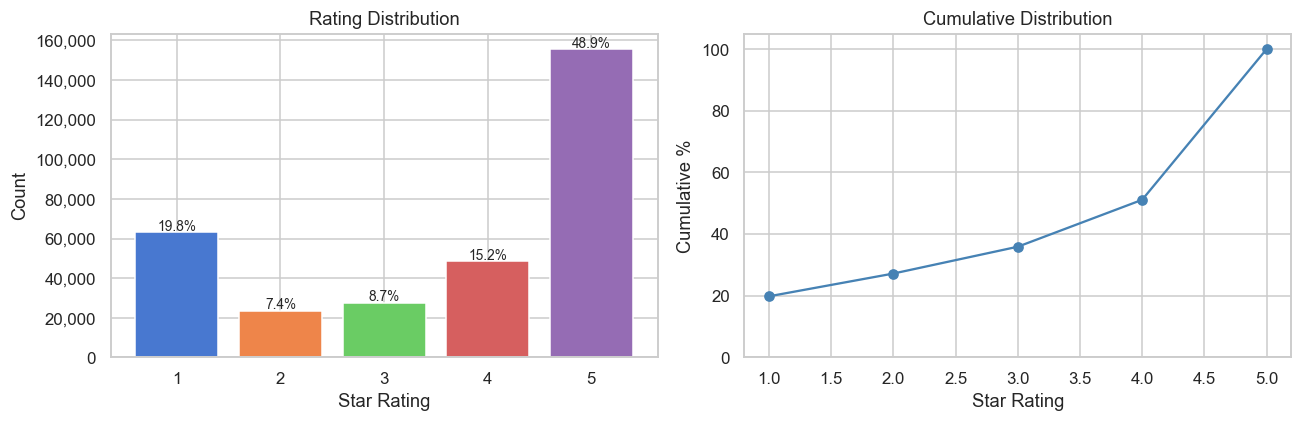

Low-star (1-2) share: 27.2%
High-star (4-5) share: 64.1%


In [11]:
# Plot star rating distribution with percentage labels and cumulative CDF
counts = df["rating"].value_counts().sort_index()
pcts = counts / counts.sum() * 100

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].bar(counts.index, counts.values, color=sns.color_palette("muted", 5))
axes[0].set_xlabel("Star Rating"); axes[0].set_ylabel("Count"); axes[0].set_title("Rating Distribution")
axes[0].yaxis.set_major_formatter(mticker.FuncFormatter(lambda x, _: f"{x:,.0f}"))
for i, (v, p) in enumerate(zip(counts.values, pcts.values)):
    axes[0].text(counts.index[i], v + 1000, f"{p:.1f}%", ha="center", fontsize=9)
axes[1].plot(counts.index, pcts.cumsum(), marker="o", color="steelblue")
axes[1].set_xlabel("Star Rating"); axes[1].set_ylabel("Cumulative %"); axes[1].set_ylim(0, 105)
axes[1].set_title("Cumulative Distribution")
plt.tight_layout(); plt.show()

print(f"Low-star (1-2) share: {(df['rating'] <= 2).mean()*100:.1f}%")
print(f"High-star (4-5) share: {(df['rating'] >= 4).mean()*100:.1f}%")

### 4.2 `verified_purchase` & `helpful_vote`

In [12]:
# Compare verified vs unverified purchase ratings and helpful_vote sparsity
print(f"Verified purchase rate: {df['verified_purchase'].mean():.1%}")
print(f"Mean rating — verified: {df.loc[df['verified_purchase'], 'rating'].mean():.2f} | "
      f"unverified: {df.loc[~df['verified_purchase'], 'rating'].mean():.2f}")
print(f"\nhelpful_vote: mean={df['helpful_vote'].mean():.1f}, "
      f"median={df['helpful_vote'].median():.0f}, max={df['helpful_vote'].max():,}")
print(f"Zero votes: {(df['helpful_vote'] == 0).sum():,} ({(df['helpful_vote'] == 0).mean():.1%})")

Verified purchase rate: 88.3%
Mean rating — verified: 3.71 | unverified: 3.31

helpful_vote: mean=2.4, median=0, max=1,953
Zero votes: 194,628 (61.1%)


### 4.3 `timestamp` — Temporal Distribution

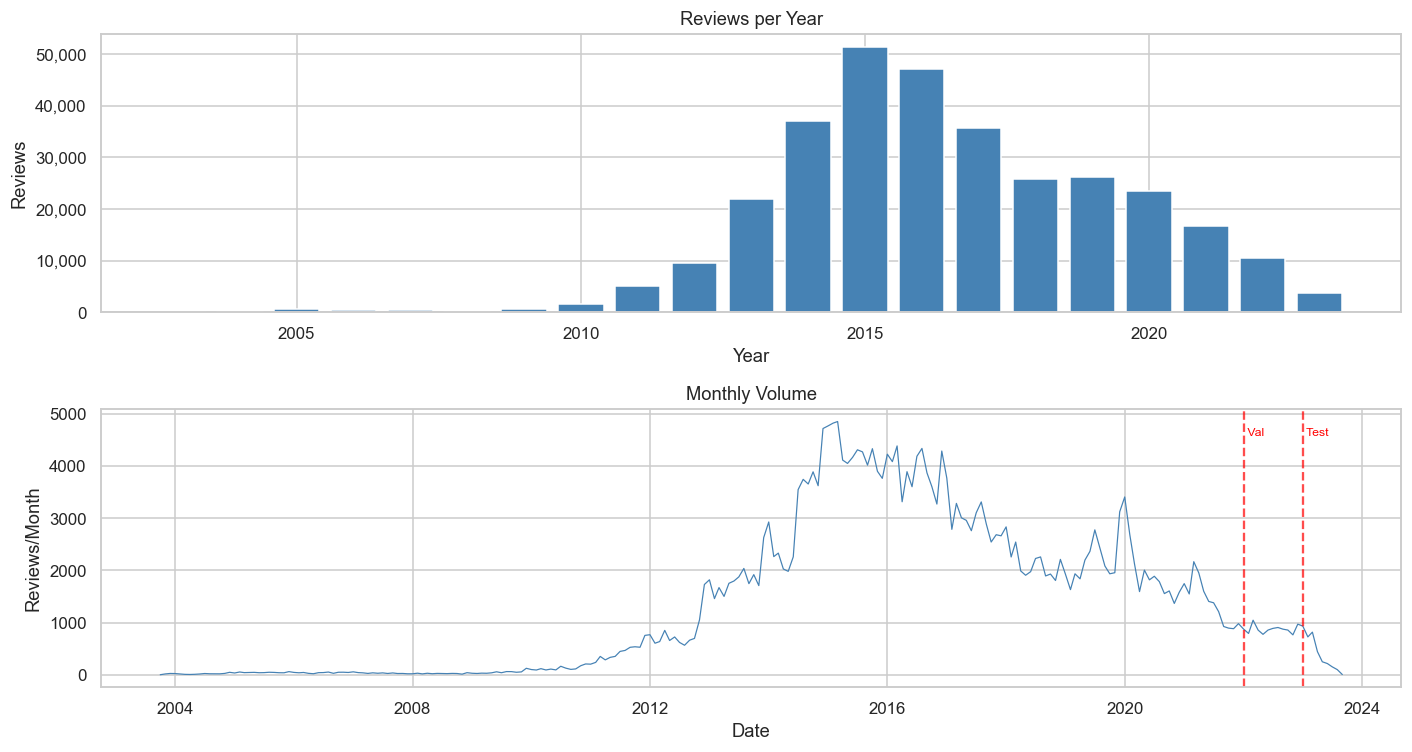

In [13]:
# Create year and year-month period columns for temporal aggregation
df["year"] = df["timestamp"].dt.year
df["ym"]   = df["timestamp"].dt.to_period("M")

fig, axes = plt.subplots(2, 1, figsize=(13, 7))
yr = df.groupby("year").size()
axes[0].bar(yr.index, yr.values, color="steelblue", edgecolor="white")
axes[0].set_xlabel("Year"); axes[0].set_ylabel("Reviews"); axes[0].set_title("Reviews per Year")
axes[0].yaxis.set_major_formatter(mticker.FuncFormatter(lambda x, _: f"{x:,.0f}"))

ym_counts = df.groupby("ym").size()
axes[1].plot(ym_counts.index.to_timestamp(), ym_counts.values, color="steelblue", linewidth=0.8)
axes[1].set_xlabel("Date"); axes[1].set_ylabel("Reviews/Month"); axes[1].set_title("Monthly Volume")
# Overlay val/test split boundaries on the monthly volume plot
for date, label in [("2022-01-01", "Val"), ("2023-01-01", "Test")]:
    axes[1].axvline(pd.Timestamp(date), color="red", linestyle="--", alpha=0.7)
    axes[1].text(pd.Timestamp(date), axes[1].get_ylim()[1]*0.9, f" {label}", color="red", fontsize=8)
plt.tight_layout(); plt.show()

### 4.4 Product-Level Metadata

In [14]:
# One row per product for product-level metadata summary
prod = df.drop_duplicates("parent_asin")[["parent_asin", "average_rating", "rating_number"]].copy()
print(f"Products: {len(prod):,}")
print(f"average_rating: mean={prod['average_rating'].mean():.2f}, std={prod['average_rating'].std():.2f}")
print(f"rating_number:  median={prod['rating_number'].median():.0f}, max={prod['rating_number'].max():,}")

# Price (product-level, ~70% null — NOT used as feature)
prod_price = df.drop_duplicates("parent_asin")["price"]
print(f"\nprice: {prod_price.notnull().mean():.1%} non-null | "
      f"median=${prod_price.median():.0f} | Decision: EXCLUDED (too sparse)")

Products: 1,501
average_rating: mean=3.97, std=0.31
rating_number:  median=333, max=51,290

price: 23.7% non-null | median=$114 | Decision: EXCLUDED (too sparse)


### 4.5 `store` — Brand Distribution

Unique stores: 77


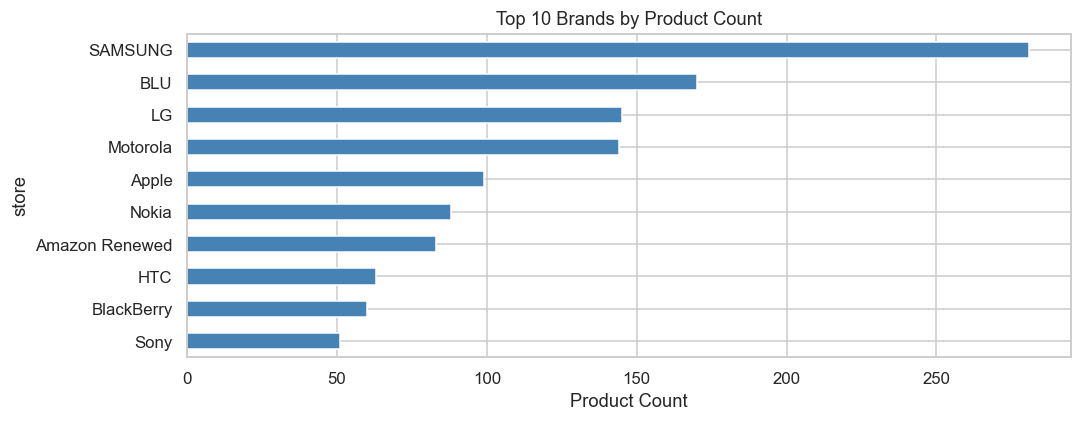

In [15]:
print(f"Unique stores: {df['store'].nunique():,}")
top_stores = df.drop_duplicates("parent_asin")["store"].value_counts().head(10)
fig, ax = plt.subplots(figsize=(10, 4))
top_stores.sort_values().plot(kind="barh", ax=ax, color="steelblue")
ax.set_xlabel("Product Count"); ax.set_title("Top 10 Brands by Product Count")
plt.tight_layout(); plt.show()

### 4.6 `split` — Temporal Split Integrity

In [16]:
# Verify temporal train/val/test split counts and date ranges
split_counts = df["split"].value_counts().reindex(["train", "val", "test"])
print("=== Split Summary ===")
for s in ["train", "val", "test"]:
    subset = df[df["split"] == s]
    print(f"  {s:5s}: {len(subset):>8,} reviews | {subset['parent_asin'].nunique():>5,} products | "
          f"{subset['timestamp'].min().date()} to {subset['timestamp'].max().date()}")

# Product overlap across splits is expected and desired for within-product drift
train_a = set(df[df["split"]=="train"]["parent_asin"])
val_a   = set(df[df["split"]=="val"]["parent_asin"])
test_a  = set(df[df["split"]=="test"]["parent_asin"])
print(f"\nProduct overlap: val in train={len(val_a & train_a)/max(len(val_a),1):.0%}, "
      f"test in train={len(test_a & train_a)/max(len(test_a),1):.0%}")
print("Overlap is expected — same products across time enables within-product drift analysis.")

=== Split Summary ===
  train:  304,210 reviews | 1,501 products | 2003-10-24 to 2021-12-31
  val  :   10,488 reviews |   459 products | 2022-01-01 to 2022-12-31
  test :    3,663 reviews |   242 products | 2023-01-01 to 2023-09-07

Product overlap: val in train=100%, test in train=100%
Overlap is expected — same products across time enables within-product drift analysis.


### 4.7 Text Length & Token Counts

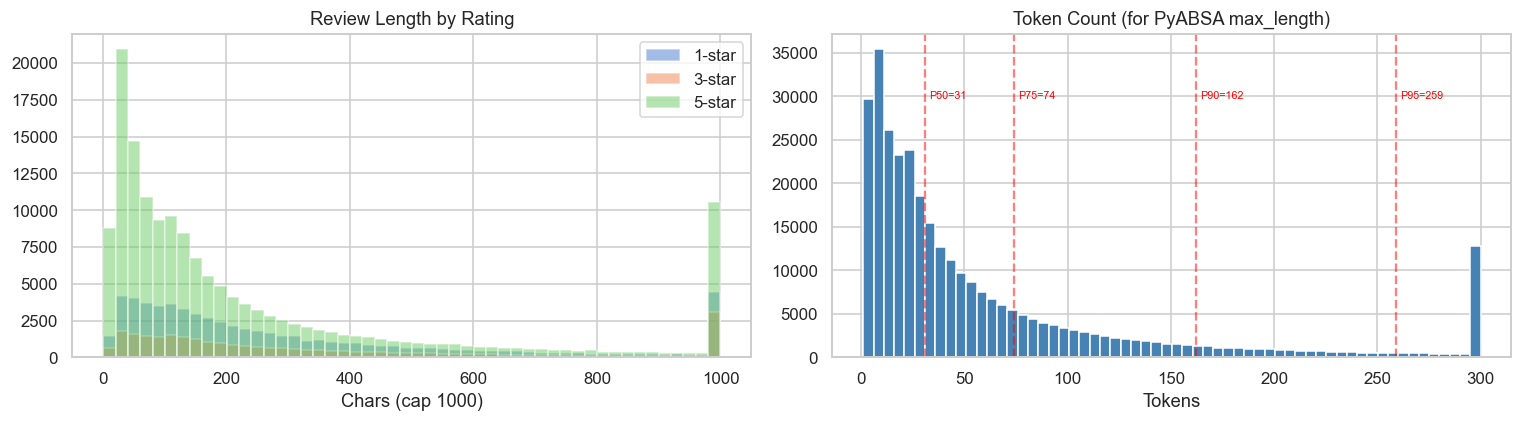

Token percentiles:
0.50     31
0.75     74
0.90    162
0.95    259
0.99    606
Name: approx_tokens, dtype: int32


In [17]:
# Compute character length and whitespace-split token count for each review
df["review_text_len"] = df["review_text"].str.len()
df["approx_tokens"]   = df["review_text"].str.split().str.len()

fig, axes = plt.subplots(1, 2, figsize=(14, 4))
for rating in [1, 3, 5]:
    axes[0].hist(df[df["rating"]==rating]["review_text_len"].clip(upper=1000),
                 bins=50, alpha=0.5, label=f"{rating}-star")
axes[0].set_xlabel("Chars (cap 1000)"); axes[0].set_title("Review Length by Rating"); axes[0].legend()

# Token percentiles inform PyABSA max_length setting (P95 used downstream)
pctiles = df["approx_tokens"].quantile([0.5, 0.75, 0.90, 0.95, 0.99])
axes[1].hist(df["approx_tokens"].clip(upper=300), bins=60, color="steelblue", edgecolor="white")
axes[1].set_xlabel("Tokens"); axes[1].set_title("Token Count (for PyABSA max_length)")
for q, v in pctiles.items():
    if v <= 300:
        axes[1].axvline(v, color="red", linestyle="--", alpha=0.5)
        axes[1].text(v+2, axes[1].get_ylim()[1]*0.8, f"P{int(q*100)}={int(v)}", fontsize=7, color="red")
plt.tight_layout(); plt.show()
print("Token percentiles:"); print(pctiles.round(0).astype(int))
token_percentiles = pctiles

### 4.8 Reviews per Product & User

In [18]:
# Summarise review-count distributions at product and user level
rev_per_prod = df.groupby("parent_asin").size()
rev_per_user = df.groupby("user_id").size()
print(f"Reviews/product: mean={rev_per_prod.mean():.0f}, median={rev_per_prod.median():.0f}, "
      f"max={rev_per_prod.max():,}")
print(f"Reviews/user:    mean={rev_per_user.mean():.1f}, median={rev_per_user.median():.0f}, "
      f"single-review users: {(rev_per_user==1).mean():.1%}")

Reviews/product: mean=212, median=121, max=6,340
Reviews/user:    mean=1.1, median=1, single-review users: 92.1%


### 4.9 `features` & `description` — Product Text Metadata

In [19]:
prod_meta = df.drop_duplicates("parent_asin")[["parent_asin", "features", "description"]].copy()
feat_null = prod_meta["features"].isna() | (prod_meta["features"].str.strip() == "")
desc_null = prod_meta["description"].isna() | (prod_meta["description"].str.strip() == "")
print(f"Features missing/empty: {feat_null.sum():,} / {len(prod_meta):,} ({feat_null.mean():.1%})")
print(f"Description missing/empty: {desc_null.sum():,} / {len(prod_meta):,} ({desc_null.mean():.1%})")

Features missing/empty: 30 / 1,501 (2.0%)
Description missing/empty: 141 / 1,501 (9.4%)


### 4.10 Correlation (Product-Level, Spearman)

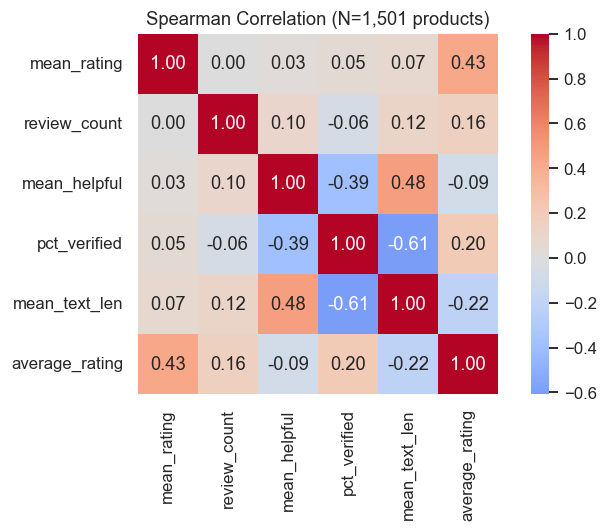

In [20]:
# Aggregate review-level metrics to product level for correlation analysis
prod_agg = df.groupby("parent_asin").agg(
    mean_rating=("rating", "mean"), review_count=("rating", "count"),
    mean_helpful=("helpful_vote", "mean"), pct_verified=("verified_purchase", "mean"),
    mean_text_len=("review_text_len", "mean"),
).reset_index()
# Join catalogue-level average_rating for comparison with computed mean_rating
prod_meta_cols = df.drop_duplicates("parent_asin")[["parent_asin", "average_rating"]].copy()
prod_agg = prod_agg.merge(prod_meta_cols, on="parent_asin", how="left")

corr_cols = ["mean_rating", "review_count", "mean_helpful", "pct_verified",
             "mean_text_len", "average_rating"]
fig, ax = plt.subplots(figsize=(7, 5))
sns.heatmap(prod_agg[corr_cols].corr(method="spearman"), annot=True, fmt=".2f",
            cmap="coolwarm", center=0, square=True, ax=ax)
ax.set_title(f"Spearman Correlation (N={len(prod_agg):,} products)")
plt.tight_layout(); plt.show()

## 5. Product Temporal Density Analysis

**The core of Phase 0.** Filter to products with enough reviews spread across enough
months to support 30-day temporal aggregation and changepoint detection.

In [21]:
# 5.1 Build Density Table
# Aggregate per-product temporal and rating statistics for density assessment
density = df.groupby("parent_asin").agg(
    total_reviews=("rating", "count"),
    first_review=("timestamp", "min"),
    last_review=("timestamp", "max"),
    mean_rating=("rating", "mean"),
    rating_std=("rating", "std"),
    pct_verified=("verified_purchase", "mean"),
).reset_index()

# Count distinct calendar months with at least one review
active_months = df.groupby("parent_asin")["ym"].nunique().rename("active_months")
density = density.merge(active_months, on="parent_asin")
# Lifespan in months (30.44 days = average month length)
density["lifespan_months"] = ((density["last_review"] - density["first_review"]).dt.days / 30.44).round(1)
density["avg_reviews_per_active_month"] = (density["total_reviews"] / density["active_months"]).round(1)

# Compute max_gap_months on ANALYSIS-GRADE months (>=3 reviews)
# Raw timestamp gaps can be bridged by months with only 1-2 reviews that will
# later be excluded in Phase 2/7. Computing gaps on qualifying months gives
# the true gap the PELT/CUSUM detectors will face.
# Analysis-grade months need >=3 reviews for stable monthly mean ratings
MIN_REVIEWS_PER_MONTH = 3

monthly_counts = (
    df.assign(ym_ts=df["timestamp"].dt.to_period("M").dt.to_timestamp())
    .groupby(["parent_asin", "ym_ts"])
    .agg(review_count=("rating", "count"))
    .reset_index()
)
qualifying_months = monthly_counts[monthly_counts["review_count"] >= MIN_REVIEWS_PER_MONTH].copy()

# Compute largest gap between consecutive qualifying months per product
def max_gap_months(group):
    months = group.sort_values()
    if len(months) < 2:
        return np.inf
    return (months.diff().dropna().dt.days / 30.44).max()

max_gaps = (
    qualifying_months.groupby("parent_asin")["ym_ts"]
    .apply(max_gap_months)
    .rename("max_gap_months")
    .round(1)
)
# Left join preserves products with no qualifying months (gap = NaN)
density = density.merge(max_gaps, on="parent_asin", how="left")
density["max_gap_months"] = density["max_gap_months"].replace([np.inf], np.nan)

# Also store count of qualifying months for downstream reference
qual_month_counts = qualifying_months.groupby("parent_asin")["ym_ts"].nunique().rename("qualifying_months")
density = density.merge(qual_month_counts, on="parent_asin", how="left")
density["qualifying_months"] = density["qualifying_months"].fillna(0).astype(int)

print(f"=== Density Table ({len(density):,} products) ===")
print(density[["total_reviews", "active_months", "qualifying_months",
               "avg_reviews_per_active_month", "max_gap_months"]].describe().round(1))

=== Density Table (1,501 products) ===
       total_reviews  active_months  qualifying_months  \
count         1501.0         1501.0             1501.0   
mean           212.1           36.5               18.3   
std            343.9           15.1               10.9   
min             17.0            9.0                0.0   
25%             76.0           26.0               10.0   
50%            121.0           34.0               15.0   
75%            212.0           44.0               23.0   
max           6340.0          124.0               75.0   

       avg_reviews_per_active_month  max_gap_months  
count                        1501.0          1499.0  
mean                            5.3             7.2  
std                             6.4             7.0  
min                             1.1             1.0  
25%                             2.6             3.0  
50%                             3.5             5.0  
75%                             5.6             9.0  
max   

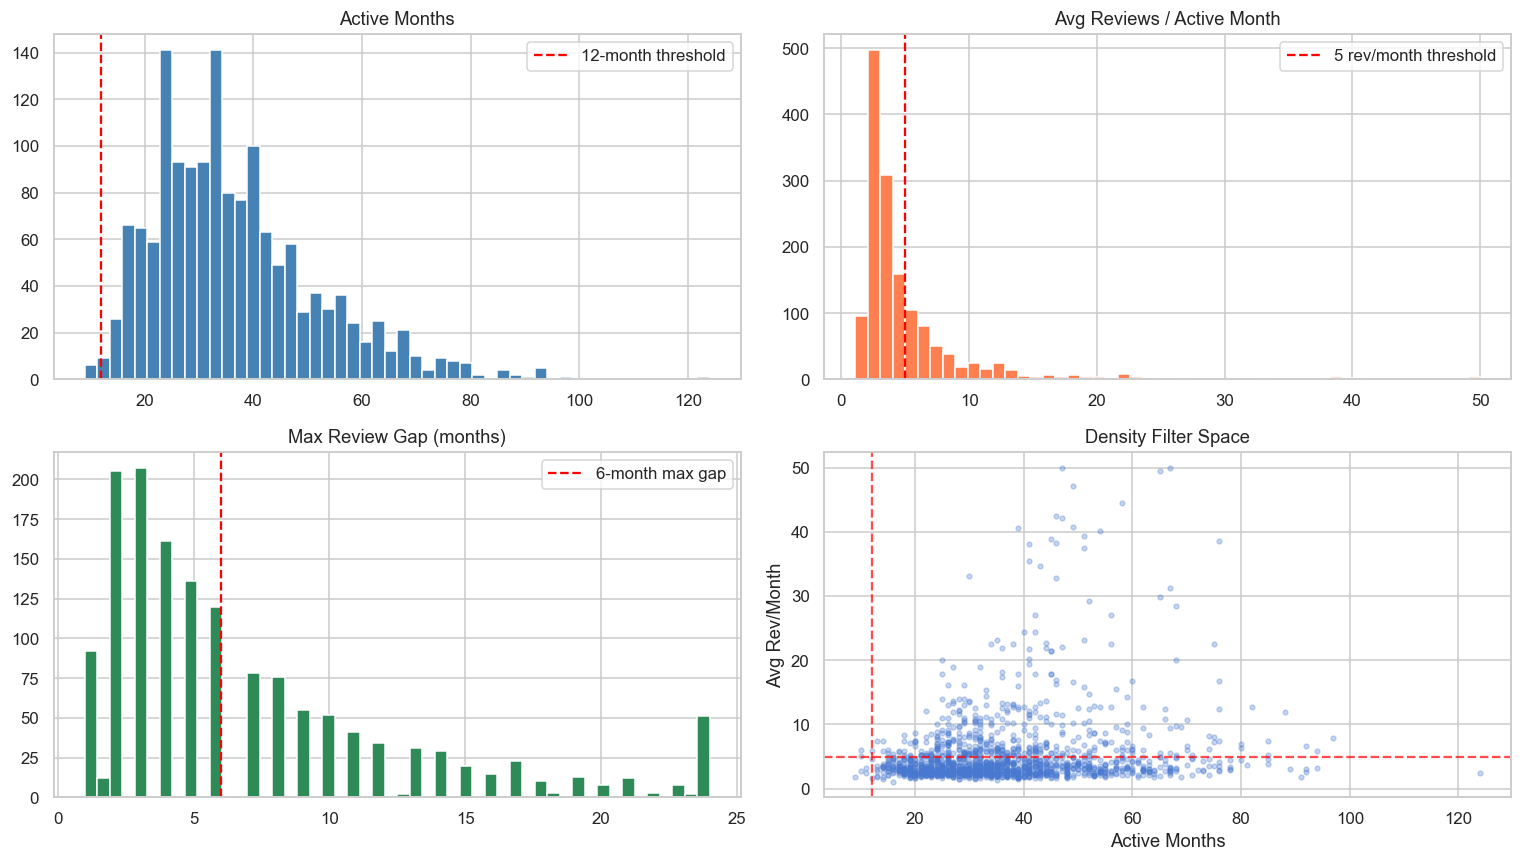

In [22]:
# 5.2 Density Distributions
# Four-panel density diagnostic: active months, rev/month, max gap, and joint scatter
fig, axes = plt.subplots(2, 2, figsize=(14, 8))
axes[0,0].hist(density["active_months"], bins=50, color="steelblue", edgecolor="white")
axes[0,0].axvline(12, color="red", linestyle="--", label="12-month threshold")
axes[0,0].set_title("Active Months"); axes[0,0].legend()

axes[0,1].hist(density["avg_reviews_per_active_month"].clip(upper=50), bins=50, color="coral", edgecolor="white")
axes[0,1].axvline(5, color="red", linestyle="--", label="5 rev/month threshold")
axes[0,1].set_title("Avg Reviews / Active Month"); axes[0,1].legend()

axes[1,0].hist(density["max_gap_months"].clip(upper=24), bins=50, color="seagreen", edgecolor="white")
axes[1,0].axvline(6, color="red", linestyle="--", label="6-month max gap")
axes[1,0].set_title("Max Review Gap (months)"); axes[1,0].legend()

axes[1,1].scatter(density["active_months"], density["avg_reviews_per_active_month"].clip(upper=50),
                  alpha=0.3, s=10)
axes[1,1].axvline(12, color="red", linestyle="--", alpha=0.7)
axes[1,1].axhline(5, color="red", linestyle="--", alpha=0.7)
axes[1,1].set_title("Density Filter Space"); axes[1,1].set_xlabel("Active Months")
axes[1,1].set_ylabel("Avg Rev/Month")
plt.tight_layout(); plt.show()

In [23]:
# 5.3 Density Filter + Sensitivity
# Sweep threshold combinations to show how many products/reviews survive each
print("=== Density Filter Sensitivity ===")
print(f"{'Mo':>4s} {'Rev/Mo':>7s} {'MaxGap':>7s} {'Prods':>7s} {'Reviews':>10s} {'%Rev':>6s}")
print("-" * 45)
for mm in [6, 9, 12, 15, 18]:
    for rv in [3, 5, 7]:
        m = (density["active_months"]>=mm) & (density["avg_reviews_per_active_month"]>=rv) & (density["max_gap_months"]<=6)
        n = m.sum()
        asins = set(density.loc[m, "parent_asin"])
        nr = df["parent_asin"].isin(asins).sum()
        tag = " <--" if (mm==12 and rv==5) else ""
        print(f"{mm:>4d} {rv:>7d} {'<=6':>7s} {n:>7,} {nr:>10,} {nr/len(df)*100:>5.1f}%{tag}")

# Chosen thresholds: 12+ months history, 5+ reviews/month, max 6-month gap
MIN_ACTIVE_MONTHS = 12
MIN_AVG_REVIEWS_PER_MONTH = 5
MAX_GAP_MONTHS = 6

dense_mask = ((density["active_months"] >= MIN_ACTIVE_MONTHS) &
              (density["avg_reviews_per_active_month"] >= MIN_AVG_REVIEWS_PER_MONTH) &
              (density["max_gap_months"] <= MAX_GAP_MONTHS))
dense_products = density[dense_mask].copy()
dense_asins = set(dense_products["parent_asin"])
n_dense_reviews = df["parent_asin"].isin(dense_asins).sum()

print(f"\n=== Applied: {MIN_ACTIVE_MONTHS}+ months, {MIN_AVG_REVIEWS_PER_MONTH}+ rev/mo, <={MAX_GAP_MONTHS}mo gap ===")
print(f"Products: {len(dense_products):,} / {len(density):,} ({len(dense_products)/len(density):.1%})")
print(f"Reviews:  {n_dense_reviews:,} / {len(df):,} ({n_dense_reviews/len(df):.1%})")

=== Density Filter Sensitivity ===
  Mo  Rev/Mo  MaxGap   Prods    Reviews   %Rev
---------------------------------------------
   6       3     <=6     670    189,761  59.6%
   6       5     <=6     340    149,339  46.9%
   6       7     <=6     200    121,968  38.3%
   9       3     <=6     670    189,761  59.6%
   9       5     <=6     340    149,339  46.9%
   9       7     <=6     200    121,968  38.3%
  12       3     <=6     667    189,613  59.6%
  12       5     <=6     338    149,227  46.9% <--
  12       7     <=6     200    121,968  38.3%
  15       3     <=6     654    188,827  59.3%
  15       5     <=6     334    148,875  46.8%
  15       7     <=6     198    121,768  38.2%
  18       3     <=6     622    186,707  58.6%
  18       5     <=6     328    148,338  46.6%
  18       7     <=6     198    121,768  38.2%

=== Applied: 12+ months, 5+ rev/mo, <=6mo gap ===
Products: 338 / 1,501 (22.5%)
Reviews:  149,227 / 318,361 (46.9%)


## 6. Preliminary Aspect Lexicon from `features`

In [24]:
# Extract manufacturer feature strings (pipe-delimited) for aspect keyword mining
prod_features = df.drop_duplicates("parent_asin")[["parent_asin", "features"]].copy()
prod_features = prod_features[prod_features["features"].notna() & (prod_features["features"].str.strip() != "")]

# Split pipe-delimited feature strings into individual phrases
all_features = []
for _, row in prod_features.iterrows():
    for f in str(row["features"]).split("|"):
        f = f.strip()
        if len(f) > 2:
            all_features.append(f.lower())

feat_series = pd.Series(all_features)
print(f"Feature phrases: {len(feat_series):,} total, {feat_series.nunique():,} unique")

# Seed lexicon mapping smartphone aspects to keyword lists for feature matching
aspect_keywords = {
    "battery":     ["battery", "charge", "charging", "power", "mah"],
    "camera":      ["camera", "photo", "video", "megapixel", "lens", "selfie"],
    "display":     ["display", "screen", "amoled", "oled", "lcd", "resolution"],
    "software":    ["android", "ios", "software", "update", "app", "operating system"],
    "build":       ["build", "design", "water", "dust", "durable", "weight"],
    "performance": ["processor", "ram", "memory", "storage", "speed", "snapdragon"],
    "connectivity":["5g", "4g", "lte", "wifi", "bluetooth", "nfc"],
    "audio":       ["speaker", "audio", "sound", "headphone", "microphone"],
}

print("\n=== Aspect Seed Lexicon ===")
for aspect, kws in aspect_keywords.items():
    n = feat_series.str.contains("|".join(kws), case=False, na=False).sum()
    print(f"  {aspect:15s}: {n:>5,} mentions")

print("\nNote: This is a seed lexicon from manufacturer specs. PyABSA may discover")
print("implicit user-defined aspects (e.g., customer service, shipping) not listed here.")

Feature phrases: 7,629 total, 4,992 unique

=== Aspect Seed Lexicon ===
  battery        :   834 mentions
  camera         : 1,469 mentions
  display        : 1,314 mentions
  software       : 1,055 mentions
  build          :   285 mentions
  performance    : 1,641 mentions
  connectivity   : 1,355 mentions
  audio          :   200 mentions

Note: This is a seed lexicon from manufacturer specs. PyABSA may discover
implicit user-defined aspects (e.g., customer service, shipping) not listed here.


## 7. Temporal Drift Analysis — Proving Drift Exists

**Operational definition of drift for Phase 0:**

> *Drift* is a sustained change in a product's monthly mean rating, low-star share
> (% of 1-2 star reviews), or rating variance, measured over **calendar-month** windows
> with a minimum support of **3 reviews per window**.

> **Survivorship bias caveat:** Our density filter (12+ active months) excludes products
> with catastrophic early failures. This analysis targets sustained products with enough
> longitudinal data for changepoint detection.

In [25]:
# 7.1 Monthly Time Series for Dense Products
gc.collect()  # free memory before building dense product subset
df_dense = df[df["parent_asin"].isin(dense_asins)].copy()
df_dense["ym_ts"] = df_dense["timestamp"].dt.to_period("M").dt.to_timestamp()

# Build monthly aggregates: mean rating, std, low-star share, volume, verified pct
monthly = (df_dense.groupby(["parent_asin", "ym_ts"])
           .agg(mean_rating=("rating", "mean"),
                rating_std=("rating", "std"),
                low_star_share=("rating", lambda x: (x <= 2).mean()),
                review_count=("rating", "count"),
                pct_verified=("verified_purchase", "mean"))
           .reset_index())

# Drop months with <3 reviews, too few for a stable monthly mean
MIN_REVIEWS_PER_MONTH = 3
monthly = monthly[monthly["review_count"] >= MIN_REVIEWS_PER_MONTH].copy()
monthly["rating_std"] = monthly["rating_std"].fillna(0)

print(f"Dense products: {df_dense['parent_asin'].nunique():,}")
print(f"Monthly windows (>={MIN_REVIEWS_PER_MONTH} reviews): {len(monthly):,}")

Dense products: 338
Monthly windows (>=3 reviews): 8,280


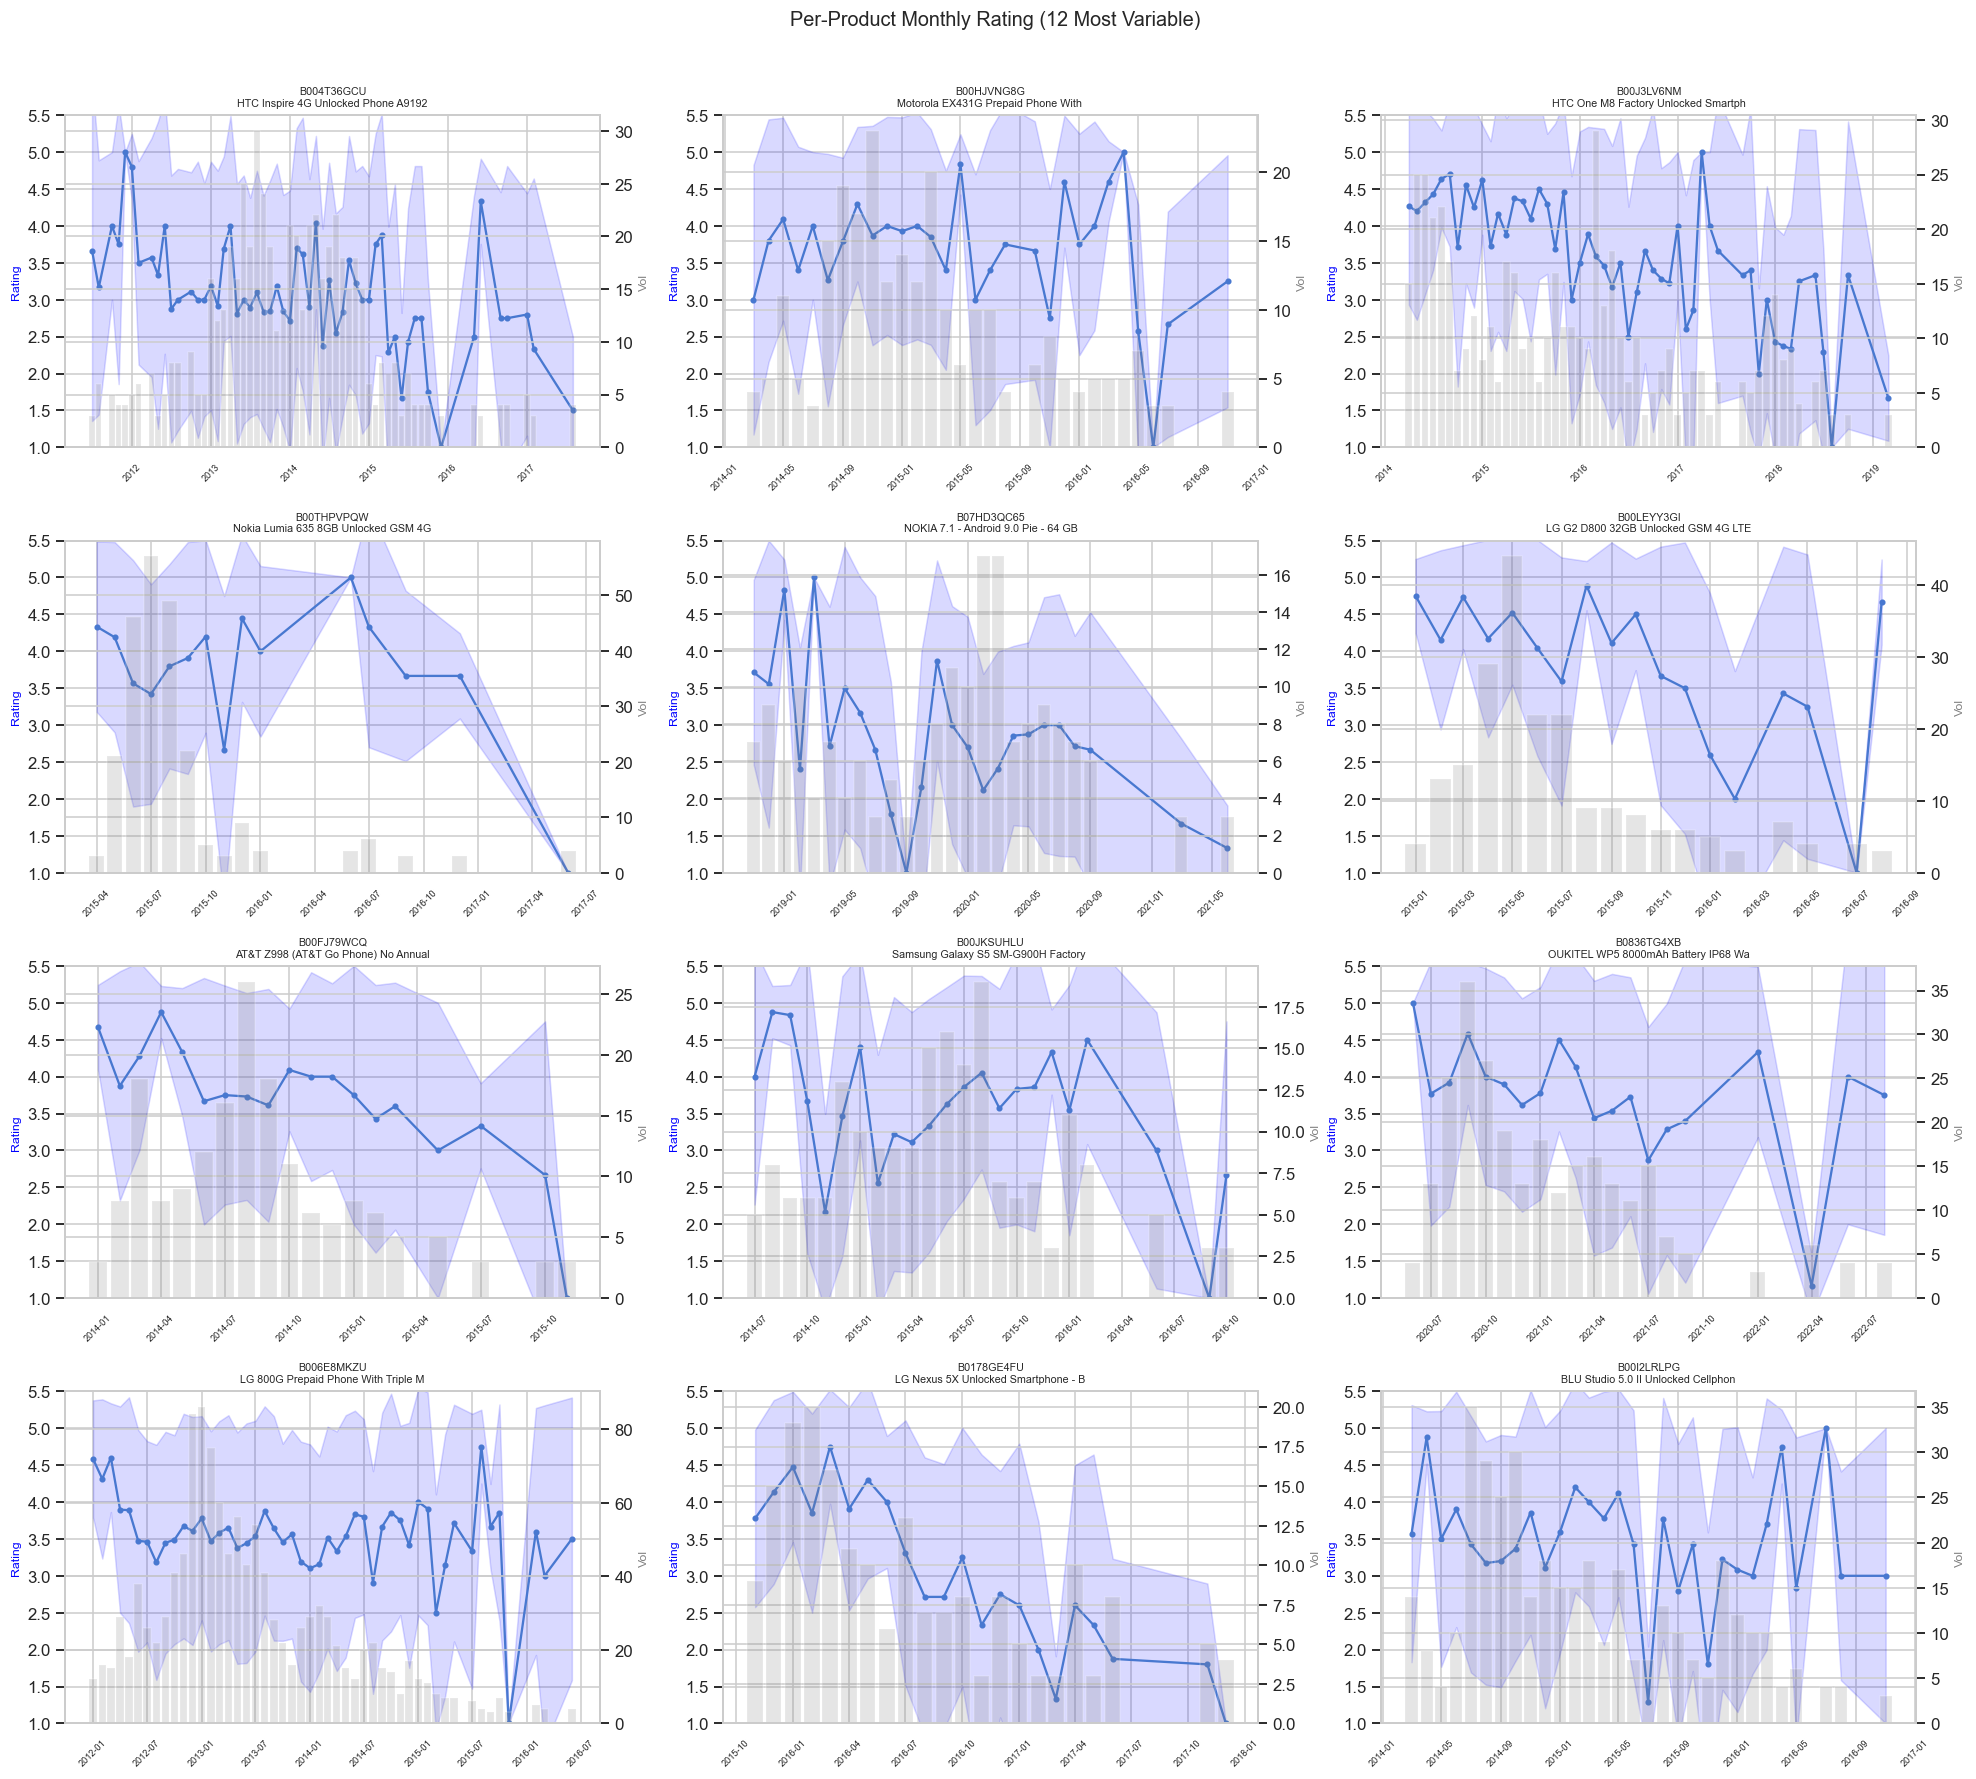

In [26]:
# 7.2 Per-Product Time Series (12 most variable)
# Rank products by rating range to find the most volatile for visual inspection
product_stats = monthly.groupby("parent_asin").agg(
    n_months=("ym_ts", "count"),
    rating_range=("mean_rating", lambda x: x.max() - x.min()),
).reset_index()
# Select 12 products with the widest rating swings
top_variable = product_stats.nlargest(12, "rating_range")

fig, axes = plt.subplots(4, 3, figsize=(18, 16))
for idx, (_, row) in enumerate(top_variable.iterrows()):
    if idx >= 12: break
    asin = row["parent_asin"]
    pd_data = monthly[monthly["parent_asin"] == asin].sort_values("ym_ts")
    ax = axes[idx//3, idx%3]
    ax2 = ax.twinx()  # secondary axis for review volume bars
    ax.plot(pd_data["ym_ts"], pd_data["mean_rating"], "b-o", markersize=3, linewidth=1.5)
    ax.fill_between(pd_data["ym_ts"], pd_data["mean_rating"]-pd_data["rating_std"],
                    pd_data["mean_rating"]+pd_data["rating_std"], alpha=0.15, color="blue")
    ax2.bar(pd_data["ym_ts"], pd_data["review_count"], width=25, alpha=0.2, color="gray")
    ax.set_ylim(1, 5.5); ax.set_ylabel("Rating", fontsize=8, color="blue")
    ax2.set_ylabel("Vol", fontsize=8, color="gray")
    title = df.loc[df["parent_asin"]==asin, "product_title"].iloc[0][:35] if "product_title" in df.columns else asin
    ax.set_title(f"{asin}\n{title}", fontsize=7)
    ax.tick_params(axis="x", rotation=45, labelsize=6)
plt.suptitle("Per-Product Monthly Rating (12 Most Variable)", fontsize=13, y=1.01)
plt.tight_layout(); plt.show()

## 8. Objective Case Study Selection

In [27]:
# 8.1 Drift Scoring
# Statistical gate: BH-FDR-corrected Mann-Whitney U on MONTHLY means (not raw
# reviews), plus rolling-delta and Cohen's d effect-size thresholds.
from statsmodels.stats.multitest import multipletests

# Cohen's d measures standardised effect size between two independent samples
def cohens_d(x, y):
    """Cohen's d for two independent samples."""
    x = pd.Series(x).dropna().astype(float)
    y = pd.Series(y).dropna().astype(float)
    if len(x) < 2 or len(y) < 2:
        return np.nan
    vx, vy = x.var(ddof=1), y.var(ddof=1)
    pooled = ((len(x) - 1) * vx + (len(y) - 1) * vy) / (len(x) + len(y) - 2)
    if pooled <= 0 or np.isnan(pooled):
        return 0.0
    return float((y.mean() - x.mean()) / np.sqrt(pooled))

# Score each dense product for drift using three complementary metrics
drift_scores = []
for asin in dense_asins:
    pd_data = monthly[monthly["parent_asin"] == asin].sort_values("ym_ts").copy()
    if len(pd_data) < 6:
        continue

    # Rolling delta: range of 6-month rolling mean captures gradual drift magnitude
    rolling_mean = pd_data["mean_rating"].rolling(6, min_periods=3).mean()
    if rolling_mean.dropna().empty:
        continue
    max_delta = float(rolling_mean.max() - rolling_mean.min())

    # Split series at chronological midpoint for early-vs-late comparison
    mid = len(pd_data) // 2
    early_months = pd_data.iloc[:mid]
    late_months = pd_data.iloc[mid:]
    if len(early_months) < 3 or len(late_months) < 3:
        continue

    # Mann-Whitney U on monthly means (not raw reviews) to avoid sample-size inflation
    early_monthly = early_months["mean_rating"]
    late_monthly = late_months["mean_rating"]
    _, monthly_p = stats.mannwhitneyu(early_monthly, late_monthly, alternative="two-sided")
    monthly_shift = float(late_monthly.mean() - early_monthly.mean())
    monthly_d = cohens_d(early_monthly, late_monthly)

    # Review-level test is overpowered (large N), kept as diagnostic only
    early_reviews = df_dense.loc[
        (df_dense["parent_asin"] == asin) &
        (df_dense["timestamp"] <= pd_data.iloc[mid]["ym_ts"]),
        "rating",
    ]
    late_reviews = df_dense.loc[
        (df_dense["parent_asin"] == asin) &
        (df_dense["timestamp"] > pd_data.iloc[mid]["ym_ts"]),
        "rating",
    ]
    if len(early_reviews) >= 10 and len(late_reviews) >= 10:
        _, review_p = stats.mannwhitneyu(early_reviews, late_reviews, alternative="two-sided")
        review_shift = float(late_reviews.mean() - early_reviews.mean())
    else:
        review_p, review_shift = 1.0, 0.0

    drift_scores.append({
        "parent_asin": asin,
        "max_rolling_delta": round(max_delta, 3),
        "monthly_shift": round(monthly_shift, 3),
        "cohens_d_monthly": round(monthly_d, 3),
        "abs_cohens_d": round(abs(monthly_d), 3),
        "mw_monthly_p_raw": float(monthly_p),
        "mw_review_p_raw": float(review_p),
        "review_level_shift": round(review_shift, 3),
        "n_months": int(len(pd_data)),
        "total_reviews": int(pd_data["review_count"].sum()),
    })

drift_df = pd.DataFrame(drift_scores)

if len(drift_df) == 0:
    print("WARNING: No products could be scored for drift.")
    drift_df["significant_drift"] = pd.Series(dtype=bool)
else:
    # Benjamini-Hochberg FDR correction controls false discovery rate across products
    drift_df["mw_monthly_p_bh"] = multipletests(
        drift_df["mw_monthly_p_raw"].fillna(1.0), alpha=0.05, method="fdr_bh"
    )[1]
    drift_df["mw_review_p_bh"] = multipletests(
        drift_df["mw_review_p_raw"].fillna(1.0), alpha=0.05, method="fdr_bh"
    )[1]

    # Three-gate filter: statistical significance AND practical effect size AND visible drift
    drift_df["significant_drift"] = (
        (drift_df["mw_monthly_p_bh"] < 0.05) &
        (drift_df["max_rolling_delta"] >= 0.5) &
        (drift_df["abs_cohens_d"] >= 0.5)
    )

n_sig = int(drift_df["significant_drift"].sum()) if len(drift_df) else 0
print(f"Products scored: {len(drift_df):,}")
print(f"Significant drift (monthly BH-FDR<0.05, delta>=0.5, |d|>=0.5): "
      f"{n_sig:,} ({n_sig/max(len(drift_df),1):.1%})")

# Sensitivity analysis: effect-size threshold
print("\n=== Sensitivity: Cohen's d threshold ===")
for d_thr in [0.3, 0.5, 0.8]:
    n = (
        (drift_df["mw_monthly_p_bh"] < 0.05) &
        (drift_df["max_rolling_delta"] >= 0.5) &
        (drift_df["abs_cohens_d"] >= d_thr)
    ).sum()
    tag = " <--" if d_thr == 0.5 else ""
    print(f"  |d|>={d_thr:.1f}: {n:,} / {len(drift_df):,} ({n/max(len(drift_df),1):.1%}){tag}")

display(
    drift_df.sort_values("max_rolling_delta", ascending=False).head(10)[[
        "parent_asin", "max_rolling_delta", "monthly_shift", "cohens_d_monthly",
        "mw_monthly_p_raw", "mw_monthly_p_bh", "mw_review_p_raw", "mw_review_p_bh",
        "n_months", "total_reviews", "significant_drift",
    ]]
)

Products scored: 338
Significant drift (monthly BH-FDR<0.05, delta>=0.5, |d|>=0.5): 111 (32.8%)

=== Sensitivity: Cohen's d threshold ===
  |d|>=0.3: 111 / 338 (32.8%)
  |d|>=0.5: 111 / 338 (32.8%) <--
  |d|>=0.8: 107 / 338 (31.7%)


,parent_asin,max_rolling_delta,monthly_shift,cohens_d_monthly,mw_monthly_p_raw,mw_monthly_p_bh,mw_review_p_raw,mw_review_p_bh,n_months,total_reviews,significant_drift
312,B019BX7F86,2.786,-0.981,-0.995,0.002804,0.017885,8.090792e-54,2.734688e-51,50,2071,True
127,B07HD2X91Q,2.519,-1.194,-1.731,0.001727,0.012417,3.902159e-10,5.072807e-09,25,327,True
47,B0178GE72K,2.432,-1.652,-2.527,0.000033,0.001369,1.157766e-21,9.783122e-20,30,472,True
321,B0178GE4FU,2.412,-1.641,-2.500,0.000233,0.003149,3.902576e-11,6.595353e-10,22,193,True
120,B00OL4DEMC,2.395,-1.324,-1.701,0.002796,0.017885,4.169586e-07,3.523300e-06,20,233,True
198,B01LZHFSBC,2.286,-1.602,-2.317,0.000329,0.003962,1.036200e-11,2.060209e-10,17,311,True
17,B00WZZ358W,2.284,-1.068,-1.328,0.000576,0.005467,2.360877e-13,6.649802e-12,44,556,True
320,B016B7INC2,2.270,-1.709,-3.054,0.000325,0.003962,2.935033e-11,5.511340e-10,20,185,True
86,B01D30XXMU,2.240,-1.331,-2.306,0.000051,0.001717,3.870391e-26,6.540960e-24,27,1466,True
62,B00VWKKHKU,2.213,-1.287,-2.480,0.000125,0.002255,3.330998e-17,1.407347e-15,25,475,True


Case study products: 5


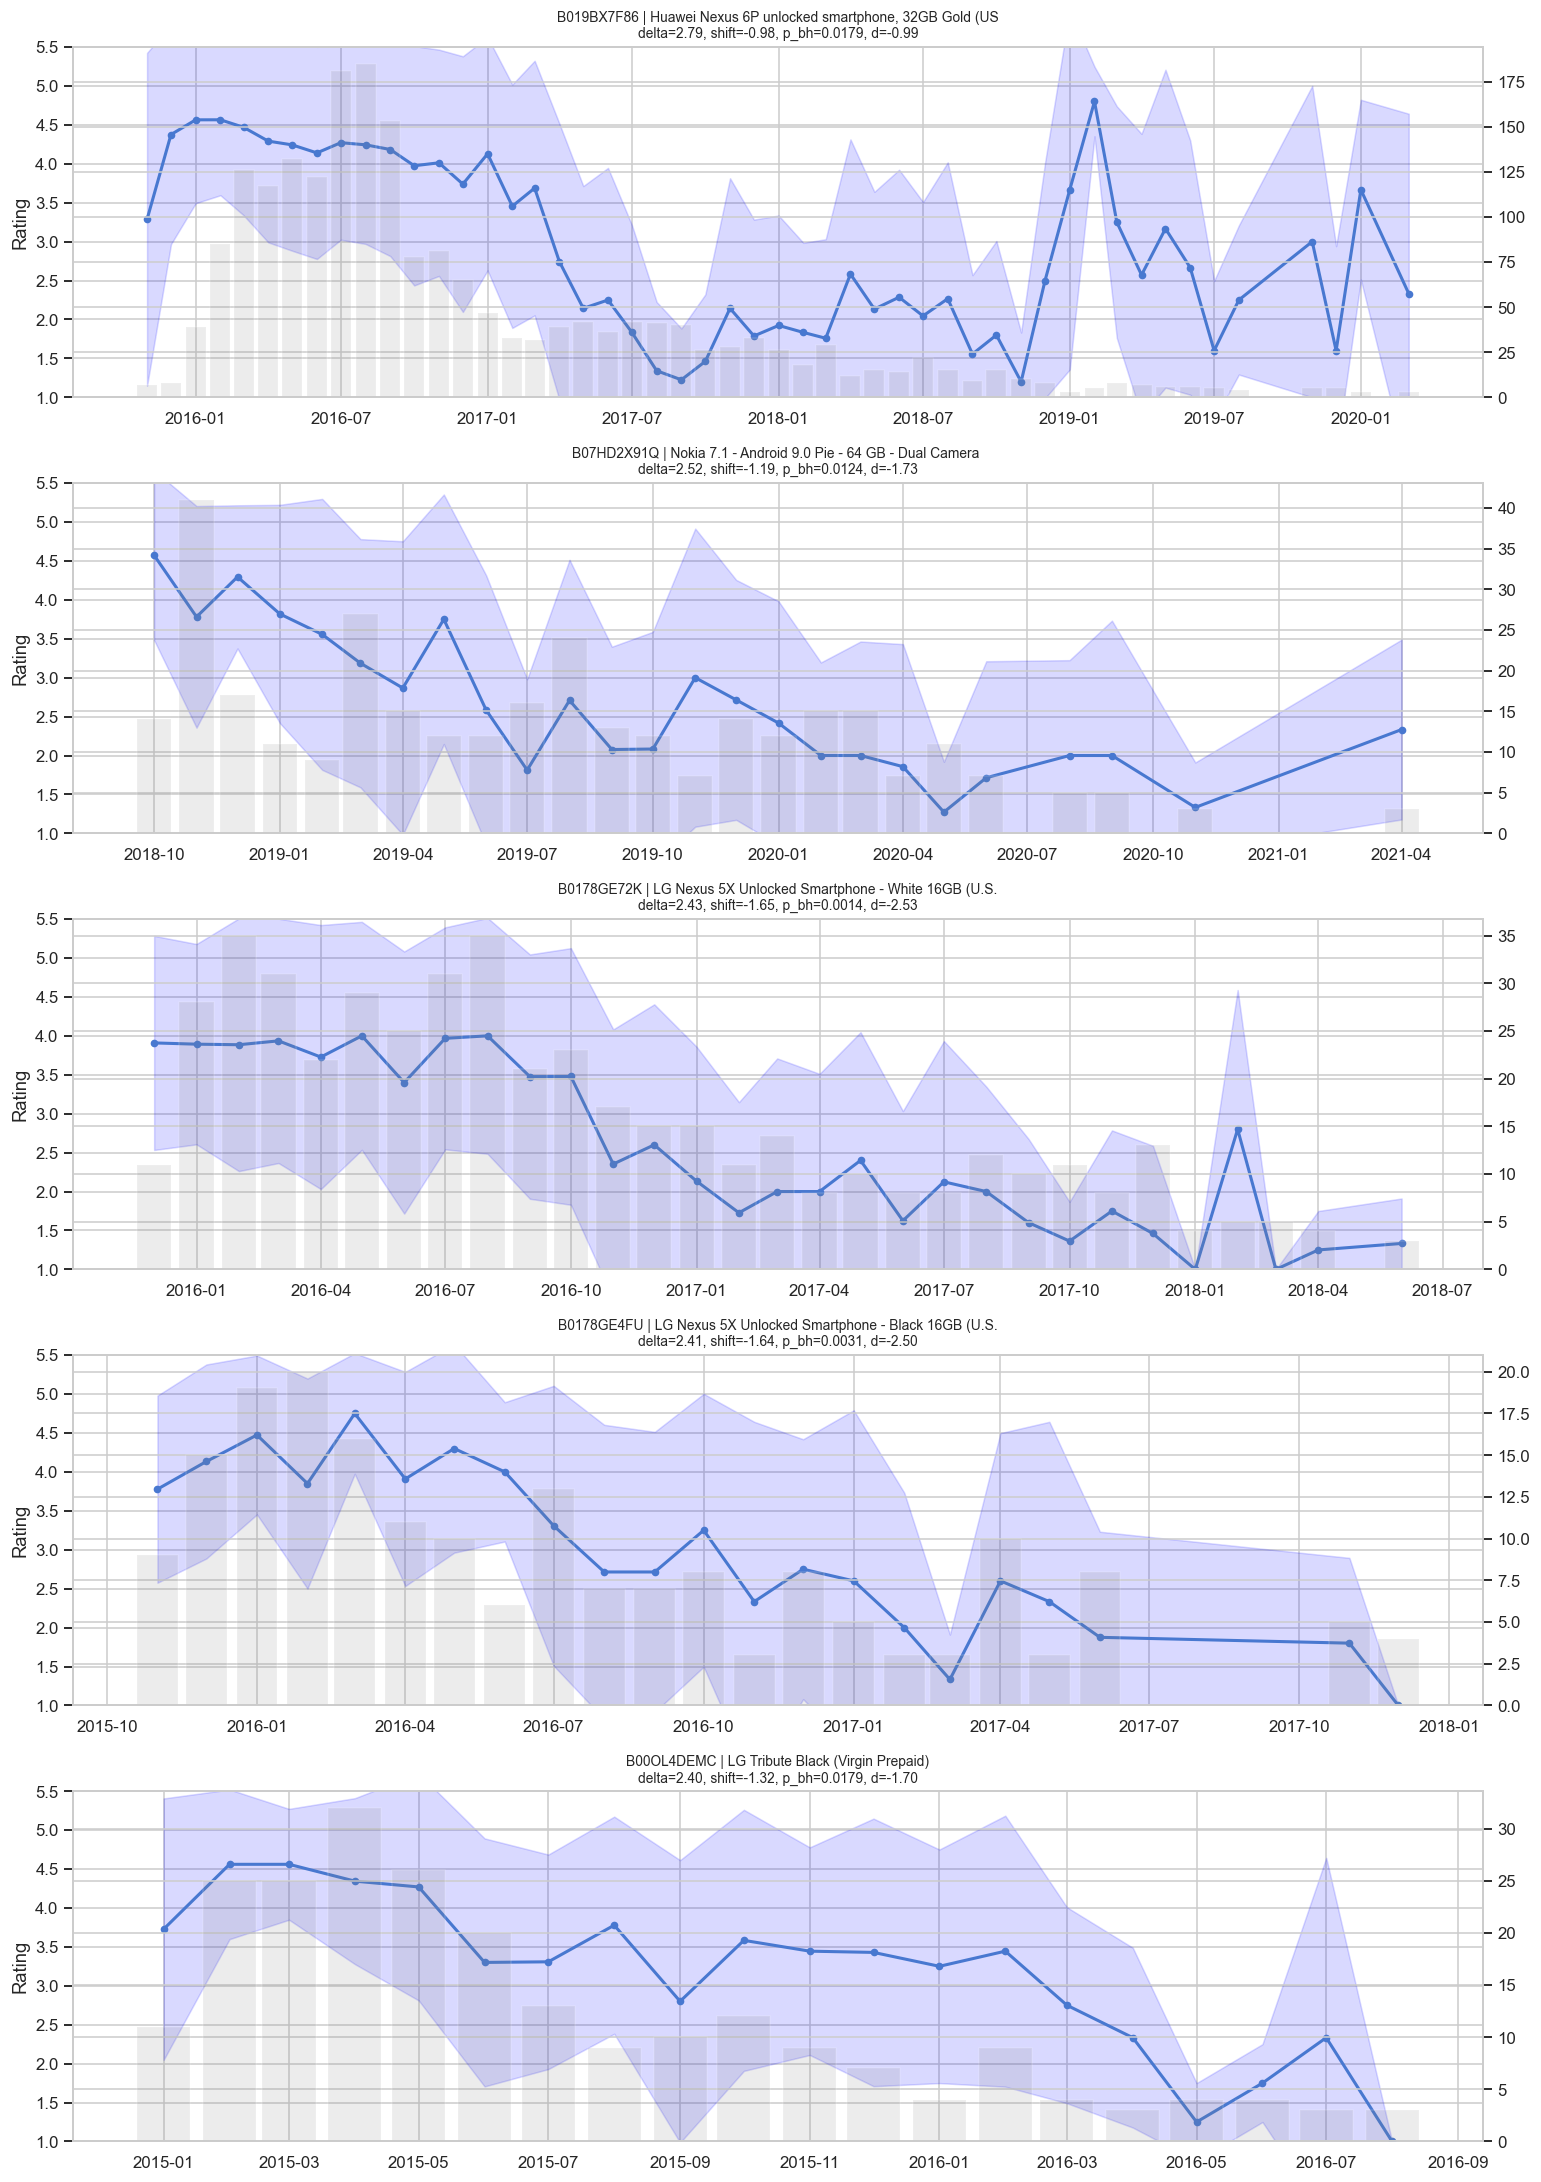

In [28]:
# 8.2 Case Study Timelines
# Select top 5 drifters (by rolling delta) from statistically significant products
case_candidates = drift_df[drift_df["significant_drift"]].nlargest(5, "max_rolling_delta")
case_asins = case_candidates["parent_asin"].tolist()
print(f"Case study products: {len(case_asins)}")

if len(case_asins) == 0:
    print("WARNING: No case studies survived. Consider relaxing thresholds.")
else:
    fig, axes = plt.subplots(len(case_asins), 1, figsize=(14, 4*len(case_asins)))
    if len(case_asins) == 1: axes = [axes]
    for idx, asin in enumerate(case_asins):
        pd_data = monthly[monthly["parent_asin"]==asin].sort_values("ym_ts")
        ax = axes[idx]; ax2 = ax.twinx()
        ax.plot(pd_data["ym_ts"], pd_data["mean_rating"], "b-o", markersize=4, linewidth=2, zorder=3)
        ax.fill_between(pd_data["ym_ts"], pd_data["mean_rating"]-pd_data["rating_std"],
                        pd_data["mean_rating"]+pd_data["rating_std"], alpha=0.15, color="blue")
        ax2.bar(pd_data["ym_ts"], pd_data["review_count"], width=25, alpha=0.15, color="gray")
        ax.set_ylim(1, 5.5); ax.set_ylabel("Rating")
        info = case_candidates[case_candidates["parent_asin"]==asin].iloc[0]
        title = df.loc[df["parent_asin"]==asin, "product_title"].iloc[0][:50] if "product_title" in df.columns else ""
        ax.set_title(f"{asin} | {title}\ndelta={info['max_rolling_delta']:.2f}, "
                     f"shift={info['monthly_shift']:+.2f}, p_bh={info['mw_monthly_p_bh']:.4f}, "
                     f"d={info['cohens_d_monthly']:.2f}", fontsize=9)
    plt.tight_layout(); plt.show()

### 8.3 Case Study Split Coverage

Verify that each case study ASIN has sufficient data in train, val, and test splits.
This is required before any modelling (Phase 1 task #1).

In [29]:
# 8.3 Case Study Split Coverage
if not case_asins:
    print("No case study ASINs available for split coverage diagnostic.")
else:
    case_df = df[df["parent_asin"].isin(case_asins)].copy()
    case_df["ym_ts"] = case_df["timestamp"].dt.to_period("M").dt.to_timestamp()

    # Check each case study ASIN has reviews in all three temporal splits
    coverage_rows = []
    for asin in case_asins:
        title = df.loc[df["parent_asin"] == asin, "product_title"].iloc[0][:55] if "product_title" in df.columns else ""
        for split in ["train", "val", "test"]:
            raw_split = case_df[(case_df["parent_asin"] == asin) & (case_df["split"] == split)]
            # Count months with >=3 reviews to verify time-series viability per split
            if len(raw_split) > 0:
                month_counts = raw_split.groupby("ym_ts").size()
                n_qual_months = (month_counts >= MIN_REVIEWS_PER_MONTH).sum()
                first_date = raw_split["timestamp"].min().date()
                last_date = raw_split["timestamp"].max().date()
            else:
                n_qual_months = 0
                first_date = pd.NaT
                last_date = pd.NaT

            coverage_rows.append({
                "parent_asin": asin,
                "product_title": title,
                "split": split,
                "review_count": len(raw_split),
                "months_ge3_reviews": int(n_qual_months),
                "first_date": first_date,
                "last_date": last_date,
            })

    split_coverage = pd.DataFrame(coverage_rows)
    print("=== Case Study Split Coverage ===")
    display(split_coverage.sort_values(["parent_asin", "split"]))

    # Warn about weak splits
    weak = split_coverage[split_coverage["review_count"] == 0]
    if len(weak) > 0:
        print("\nWARNING: Some case study ASINs have EMPTY splits:")
        display(weak[["parent_asin", "split"]])
    else:
        print("\nAll case study ASINs have data in all splits.")

=== Case Study Split Coverage ===


,parent_asin,product_title,split,review_count,months_ge3_reviews,first_date,last_date
14,B00OL4DEMC,LG Tribute Black (Virgin Prepaid),test,0,0,NaT,NaT
12,B00OL4DEMC,LG Tribute Black (Virgin Prepaid),train,247,20,2014-12-31,2020-07-07
13,B00OL4DEMC,LG Tribute Black (Virgin Prepaid),val,0,0,NaT,NaT
11,B0178GE4FU,LG Nexus 5X Unlocked Smartphone - Black 16GB (...,test,0,0,NaT,NaT
9,B0178GE4FU,LG Nexus 5X Unlocked Smartphone - Black 16GB (...,train,207,22,2015-11-20,2020-06-06
10,B0178GE4FU,LG Nexus 5X Unlocked Smartphone - Black 16GB (...,val,2,0,2022-01-02,2022-05-17
8,B0178GE72K,LG Nexus 5X Unlocked Smartphone - White 16GB (...,test,0,0,NaT,NaT
6,B0178GE72K,LG Nexus 5X Unlocked Smartphone - White 16GB (...,train,481,30,2015-11-20,2020-03-10
7,B0178GE72K,LG Nexus 5X Unlocked Smartphone - White 16GB (...,val,1,0,2022-01-11,2022-01-11
2,B019BX7F86,"Huawei Nexus 6P unlocked smartphone, 32GB Gold...",test,0,0,NaT,NaT


,parent_asin,split
2,B019BX7F86,test
8,B0178GE72K,test
11,B0178GE4FU,test
13,B00OL4DEMC,val
14,B00OL4DEMC,test


## 9. Confound Analysis — Composition Shift vs Within-Product Drift

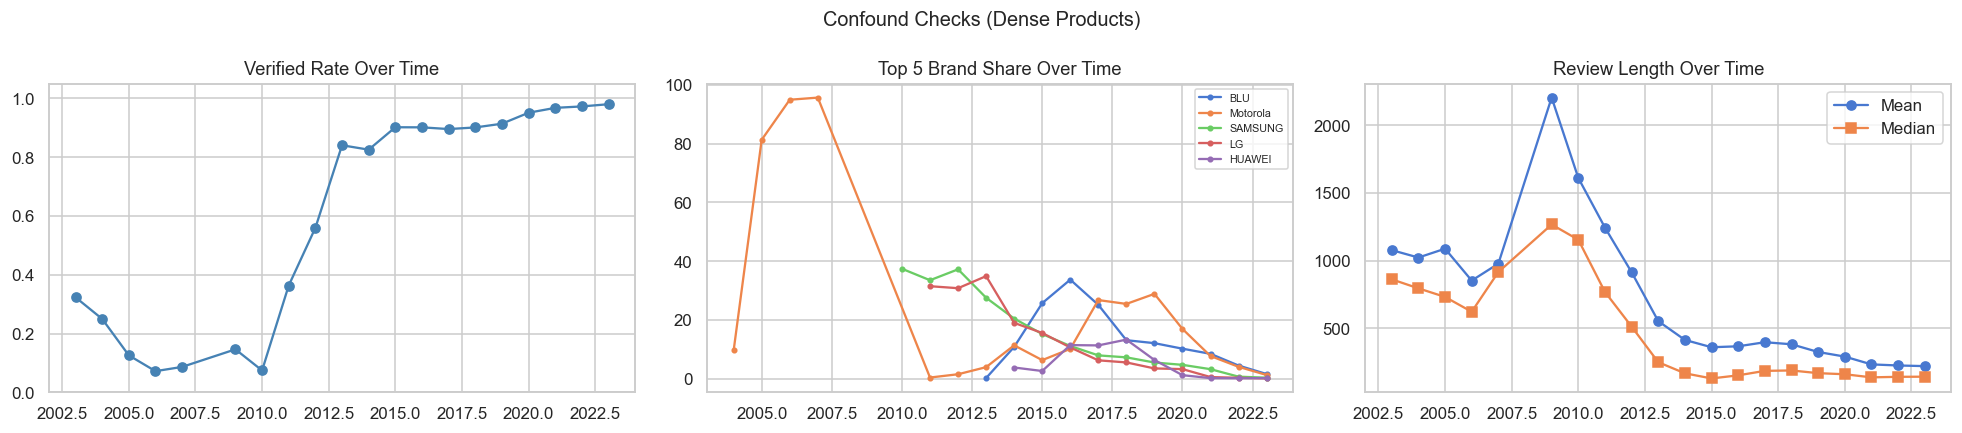

Per-product analysis controls for composition shift.
Verified rate and review length trends are noted as potential confounds.


In [30]:
# Three confound checks: verified rate trend, brand composition shift, review length drift
fig, axes = plt.subplots(1, 3, figsize=(18, 4))

# Track verified purchase ratio over time to detect platform policy changes
vp_trend = df_dense.groupby("year")["verified_purchase"].mean()
axes[0].plot(vp_trend.index, vp_trend.values, "o-", color="steelblue")
axes[0].set_title("Verified Rate Over Time"); axes[0].set_ylim(0, 1.05)

# Monitor top-5 brand share over time to check for composition shift confound
non_oem = {"Amazon Renewed", "Unknown"}
brand_counts = df_dense[~df_dense["store"].isin(non_oem)]["store"].value_counts()
top_brands = brand_counts.head(5).index
for brand in top_brands:
    bc = df_dense[df_dense["store"]==brand].groupby("year").size()
    total = df_dense.groupby("year").size()
    share = (bc / total * 100).dropna()
    axes[1].plot(share.index, share.values, "o-", label=brand, markersize=3)
axes[1].set_title("Top 5 Brand Share Over Time"); axes[1].legend(fontsize=7)

# Review length over time
len_trend = df_dense.groupby("year")["review_text_len"].agg(["mean", "median"])
axes[2].plot(len_trend.index, len_trend["mean"], "o-", label="Mean")
axes[2].plot(len_trend.index, len_trend["median"], "s-", label="Median")
axes[2].set_title("Review Length Over Time"); axes[2].legend()

plt.suptitle("Confound Checks (Dense Products)", fontsize=13)
plt.tight_layout(); plt.show()

print("Per-product analysis controls for composition shift.")
print("Verified rate and review length trends are noted as potential confounds.")

## 10. Phase 0 Conclusion — Go / No-Go Verdict

In [31]:
print("=" * 70)
print("PHASE 0 CONCLUSION: SENTINELDRIFT EDA")
print("=" * 70)

print(f"\n1. DATASET (post-cleaning)")
print(f"   Rows:     {len(df):,}")
print(f"   Products: {df['parent_asin'].nunique():,}")
print(f"   Range:    {df['timestamp'].min().date()} to {df['timestamp'].max().date()}")

print(f"\n2. DENSITY FILTERING")
print(f"   Threshold: {MIN_ACTIVE_MONTHS}+ months, {MIN_AVG_REVIEWS_PER_MONTH}+ rev/mo, "
      f"<={MAX_GAP_MONTHS}mo gap (analysis-grade)")
print(f"   Dense products: {len(dense_products):,}")
print(f"   Dense reviews:  {n_dense_reviews:,} ({n_dense_reviews/len(df):.1%})")

print(f"\n3. DRIFT EVIDENCE (BH-FDR corrected, Cohen's d >= 0.5)")
print(f"   Significant drifters: {n_sig:,} / {len(drift_df):,} ({n_sig/max(len(drift_df),1):.1%})")
print(f"   Case studies:         {len(case_asins)}")
print(f"   Max rolling delta:    {drift_df['max_rolling_delta'].max():.2f}")

print(f"\n4. PARAMETERS FOR DOWNSTREAM")
print(f"   Aspect lexicon: {len(aspect_keywords)} aspects")
print(f"   PyABSA max_length: ~{int(token_percentiles[0.95])} tokens (P95)")
print(f"   Surge-day reviews: {df['is_surge_day'].sum():,} flagged (retained)")

# GO requires at least 3 significant drifters and 3 case study products
go = n_sig >= 3 and len(case_asins) >= 3
print(f"\n{'='*70}")
print(f"VERDICT: ** {'GO' if go else 'CONDITIONAL GO'} **")
print(f"{'='*70}")

PHASE 0 CONCLUSION: SENTINELDRIFT EDA

1. DATASET (post-cleaning)
   Rows:     318,361
   Products: 1,501
   Range:    2003-10-24 to 2023-09-07

2. DENSITY FILTERING
   Threshold: 12+ months, 5+ rev/mo, <=6mo gap (analysis-grade)
   Dense products: 338
   Dense reviews:  149,227 (46.9%)

3. DRIFT EVIDENCE (BH-FDR corrected, Cohen's d >= 0.5)
   Significant drifters: 111 / 338 (32.8%)
   Case studies:         5
   Max rolling delta:    2.79

4. PARAMETERS FOR DOWNSTREAM
   Aspect lexicon: 8 aspects
   PyABSA max_length: ~259 tokens (P95)
   Surge-day reviews: 62 flagged (retained)

VERDICT: ** GO **


## 11. Export Clean Dataset & Artifacts

In [32]:
# Resolve repo root for export paths (works whether run from notebooks/ or repo root)
notebook_dir = os.path.dirname(os.path.abspath("__file__"))
repo_root = os.path.dirname(notebook_dir) if os.path.basename(notebook_dir) == "notebooks" else notebook_dir
out_dir = os.path.join(repo_root, "data", "processed")
os.makedirs(out_dir, exist_ok=True)

# Canonical column list; only export columns that exist in the cleaned dataframe
EXPORT_COLS = ["user_id", "review_text", "review_title", "review_text_combined",
               "rating", "timestamp", "parent_asin", "verified_purchase",
               "helpful_vote", "product_title", "split", "store",
               "categories", "features", "description", "is_surge_day"]
export_cols = [c for c in EXPORT_COLS if c in df.columns]

# Export clean dataset in both parquet (fast) and compressed CSV (portable) formats
clean_path = os.path.join(out_dir, "smartphone_reviews_clean.parquet")
df[export_cols].to_parquet(clean_path, index=False)
print(f"Saved: {clean_path} ({len(df):,} rows)")

csv_path = os.path.join(out_dir, "cellphone_reviews_clean.csv.gz")
df[export_cols].to_csv(csv_path, index=False, compression="gzip")
print(f"Saved: {csv_path}")

# Export density table with qualifying_months for downstream density-aware filtering
density_path = os.path.join(out_dir, "product_density.csv")
density.to_csv(density_path, index=False)
print(f"Saved: {density_path} ({len(density):,} products, {len(dense_products):,} dense)")

# Export drift scores with BH-FDR corrected p-values and effect sizes
drift_path = os.path.join(out_dir, "drift_scores.csv")
drift_df.to_csv(drift_path, index=False)
print(f"Saved: {drift_path}")

# Export selected case study ASINs as a simple text file for downstream notebooks
if case_asins:
    case_path = os.path.join(out_dir, "case_study_asins.txt")
    with open(case_path, "w") as f:
        for asin in case_asins:
            f.write(asin + "\n")
    print(f"Saved: {case_path}")

# Sanity-check assertions before declaring the dataset ready
assert df["review_text"].isna().sum() == 0, "Null review_text found"
assert (df["review_text"].str.strip() != "").all(), "Empty review_text found"
assert df["rating"].isin([1, 2, 3, 4, 5]).all(), "Invalid ratings"
assert df["helpful_vote"].min() >= 0, "Negative helpful_vote"
assert "review_text_combined" in df.columns, "review_text_combined column missing"
assert "is_surge_day" in df.columns, "is_surge_day column missing"
print(f"\nAll assertions passed. Dataset ready for downstream pipeline.")

Saved: c:\Users\alexi\Desktop\Warwick-Projects\Python\sentineldrift\data\processed\smartphone_reviews_clean.parquet (318,361 rows)
Saved: c:\Users\alexi\Desktop\Warwick-Projects\Python\sentineldrift\data\processed\cellphone_reviews_clean.csv.gz
Saved: c:\Users\alexi\Desktop\Warwick-Projects\Python\sentineldrift\data\processed\product_density.csv (1,501 products, 338 dense)
Saved: c:\Users\alexi\Desktop\Warwick-Projects\Python\sentineldrift\data\processed\drift_scores.csv
Saved: c:\Users\alexi\Desktop\Warwick-Projects\Python\sentineldrift\data\processed\case_study_asins.txt

All assertions passed. Dataset ready for downstream pipeline.
